In [49]:
# ============================================================
# SECTION 1: IMPORTS AND FINAL MODEL SETTINGS
# ============================================================

import numpy as np
import pandas as pd
import json
import hashlib

from pathlib import Path
from itertools import combinations
from datetime import datetime

from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import SGDClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)


# ============================================================
# CONTEXT INPUTS
# ============================================================

LOCATIONS = [
    "Home",
    "Work",
    "Travel",
    "Social"
]

RELATIONSHIPS = [
    "Family",
    "Friend",
    "Acquaintance",
    "Colleague"
]

TIMES = [
    "Morning",
    "Afternoon",
    "Evening",
    "Night"
]

DAYS = [
    "Weekday",
    "Weekend"
]


MODEL_INPUT_FEATURES = [
    "Location",
    "Relationship",
    "Time",
    "Day"
]


# ============================================================
# CALL RECORD COLUMNS


RECORD_COLUMNS = [
    "Location",
    "Relationship",
    "Time",
    "Day",
    "Duration_Minutes",
    "Timestamp",
    "Modalities"
]


# ============================================================
# MODALITIES
# ============================================================

MODALITIES = [
    "Audio",
    "Visual",
    "Smell",
    "Taste",
    "Haptics"
]


MODALITY_COMBINATIONS = []

for number_of_modalities in range(
    1,
    len(MODALITIES) + 1
):

    for combination in combinations(
        MODALITIES,
        number_of_modalities
    ):

        MODALITY_COMBINATIONS.append(
            combination
        )


VALID_COMBINATIONS = [

    " + ".join(
        combination
    )

    for combination in MODALITY_COMBINATIONS
]


# ============================================================
# FINAL SGD SETTINGS
# ============================================================

TEST_SIZE = 0.20

RANDOM_STATE = 42

TRAINING_EPOCHS = 20

NEW_CALL_BATCH_SIZE = 10


print(
    "Final SGD configuration loaded."
)

print(
    "Context inputs:",
    MODEL_INPUT_FEATURES
)

print(
    "Possible modality combinations:",
    len(VALID_COMBINATIONS)
)

print(
    "Historical preference model: REMOVED"
)

Final SGD configuration loaded.
Context inputs: ['Location', 'Relationship', 'Time', 'Day']
Possible modality combinations: 31
Historical preference model: REMOVED


In [50]:
# ============================================================
# SECTION 2: LOAD HISTORICAL DATASET
# ============================================================

file_name = input(
    "Enter the historical CSV file name or full path: "
).strip()


if not Path(file_name).exists():

    raise FileNotFoundError(
        "Historical dataset not found."
    )


historical_data = pd.read_csv(
    file_name
)


print(
    "\nHistorical dataset loaded successfully."
)

print(
    "File:",
    file_name
)

print(
    "Number of calls:",
    len(historical_data)
)


display(
    historical_data.head()
)

Enter the historical CSV file name or full path:  C:\Users\slaye\Downloads\Thesis Resources\mulsemedia_cumulative_1000_model_labels.csv



Historical dataset loaded successfully.
File: C:\Users\slaye\Downloads\Thesis Resources\mulsemedia_cumulative_1000_model_labels.csv
Number of calls: 1000


,Location,Relationship,Time,Day,Duration_Minutes,Timestamp,Modalities
0,Social,Friend,Afternoon,Weekend,70,2025-01-05 08:15:00,Audio + Visual + Smell + Taste + Haptics
1,Work,Acquaintance,Morning,Weekend,11,2025-01-06 03:32:00,Audio
2,Work,Family,Morning,Weekend,8,2025-01-06 19:24:00,Audio
3,Social,Acquaintance,Night,Weekday,31,2025-01-07 09:53:00,Audio + Visual + Haptics
4,Work,Friend,Night,Weekday,30,2025-01-08 02:53:00,Audio + Visual + Haptics


In [51]:
# ============================================================
# SECTION 3: VALIDATE CALL DATA
# ============================================================

def prepare_call_data(data):

    data = data.copy()


    # --------------------------------------------------------
    # Required columns
    # --------------------------------------------------------

    missing_columns = [

        column

        for column in RECORD_COLUMNS

        if column not in data.columns

    ]


    if missing_columns:

        raise ValueError(

            "Missing required columns: "

            + ", ".join(
                missing_columns
            )

        )


    data = data[
        RECORD_COLUMNS
    ].copy()


    # --------------------------------------------------------
    # Clean context inputs
    # --------------------------------------------------------

    for column in MODEL_INPUT_FEATURES:

        data[column] = (

            data[column]

            .astype(str)

            .str.strip()

            .str.title()

        )


    # --------------------------------------------------------
    # Clean modality target
    # --------------------------------------------------------

    data[
        "Modalities"
    ] = (

        data[
            "Modalities"
        ]

        .astype(str)

        .str.strip()

    )


    # --------------------------------------------------------
    # Duration
    # --------------------------------------------------------

    data[
        "Duration_Minutes"
    ] = pd.to_numeric(

        data[
            "Duration_Minutes"
        ],

        errors="coerce"

    )


    # --------------------------------------------------------
    # Timestamp
    # --------------------------------------------------------

    data[
        "Timestamp"
    ] = pd.to_datetime(

        data[
            "Timestamp"
        ],

        errors="coerce"

    )


    # --------------------------------------------------------
    # Invalid / missing values
    # --------------------------------------------------------

    if data.isnull().any().any():

        bad_columns = (

            data.columns[
                data.isnull().any()
            ]

            .tolist()

        )


        raise ValueError(

            "Missing or invalid values found in: "

            + ", ".join(
                bad_columns
            )

        )


    # --------------------------------------------------------
    # Valid context categories
    # --------------------------------------------------------

    valid_categories = {

        "Location":
            LOCATIONS,

        "Relationship":
            RELATIONSHIPS,

        "Time":
            TIMES,

        "Day":
            DAYS

    }


    for column, allowed_values in valid_categories.items():


        invalid = (

            ~data[
                column
            ].isin(
                allowed_values
            )

        )


        if invalid.any():

            raise ValueError(

                f"Invalid {column} value(s): "

                + str(

                    data.loc[
                        invalid,
                        column
                    ]

                    .unique()

                    .tolist()

                )

            )


    # --------------------------------------------------------
    # Duration must be positive
    # --------------------------------------------------------

    if (

        data[
            "Duration_Minutes"
        ]

        <= 0

    ).any():

        raise ValueError(

            "Duration_Minutes must be greater than zero."

        )


    # --------------------------------------------------------
    # Validate output classes
    # --------------------------------------------------------

    invalid_modalities = (

        ~data[
            "Modalities"
        ].isin(
            VALID_COMBINATIONS
        )

    )


    if invalid_modalities.any():

        raise ValueError(

            "Invalid modality combination(s): "

            + str(

                data.loc[
                    invalid_modalities,
                    "Modalities"
                ]

                .unique()

                .tolist()

            )

        )


    return (

        data

        .reset_index(
            drop=True
        )

    )


historical_data = prepare_call_data(
    historical_data
)


print(
    "Dataset validated successfully."
)

print(
    "Total calls:",
    len(historical_data)
)

print(
    "Observed modality classes:",
    historical_data[
        "Modalities"
    ].nunique()
)

Dataset validated successfully.
Total calls: 1000
Observed modality classes: 8


In [52]:
# ============================================================
# SECTION 4: STRICT 80/20 SHARED TRAIN-TEST SPLIT
# SAME ROWS FOR SGD AND RANDOM FOREST
# ============================================================

import numpy as np
import pandas as pd
from pathlib import Path


# ============================================================
# SETTINGS
# ============================================================

TEST_SIZE = 0.20
RANDOM_STATE = 42


# ============================================================
# 1. RESET ROW NUMBERS
#
# Dataset_Row uniquely identifies each row in the cumulative
# dataset and allows RF and SGD to use exactly the same split.
# ============================================================

historical_data = (

    historical_data

    .copy()

    .reset_index(drop=True)

)


historical_data[
    "Dataset_Row"
] = np.arange(

    1,

    len(historical_data) + 1

)


total_calls = len(
    historical_data
)


# ============================================================
# 2. REQUIRED EXACT SPLIT SIZE
# ============================================================

expected_test_calls = int(

    total_calls * TEST_SIZE

)


expected_training_calls = (

    total_calls
    -
    expected_test_calls

)


# Planned evaluation datasets
expected_sizes = {

    250: (200, 50),

    500: (400, 100),

    750: (600, 150),

    1000: (800, 200)

}


if total_calls in expected_sizes:

    required_train, required_test = (

        expected_sizes[
            total_calls
        ]

    )


    if (
        expected_training_calls != required_train
        or
        expected_test_calls != required_test
    ):

        raise RuntimeError(

            "The calculated split does not match "
            "the required strict 80/20 split."

        )


# ============================================================
# 3. CUSTOM STRICT STRATIFIED SPLITTER
# ============================================================

def strict_safe_stratified_split(

    data,

    target_column="Modalities",

    test_fraction=0.20,

    random_state=42

):


    rng = np.random.default_rng(

        random_state

    )


    number_of_rows = len(
        data
    )


    required_test_rows = int(

        number_of_rows
        *
        test_fraction

    )


    required_train_rows = (

        number_of_rows
        -
        required_test_rows

    )


    class_counts = (

        data[
            target_column
        ]

        .value_counts()

    )


    maximum_test_possible = int(

        sum(

            max(
                count - 1,
                0
            )

            for count
            in class_counts.values

        )

    )


    if required_test_rows > maximum_test_possible:

        raise ValueError(

            "Exact 80/20 split is impossible while "
            "keeping at least one training example "
            "from every class."

        )


    # ========================================================
    # INITIAL TEST ALLOCATION BY CLASS
    # ========================================================

    class_information = {}


    for class_name, group in (

        data.groupby(
            target_column
        )

    ):


        indices = group.index.to_numpy()


        indices = rng.permutation(

            indices

        )


        class_count = len(
            indices
        )


        ideal_test_count = (

            class_count
            *
            test_fraction

        )


        # Singleton classes must stay in training
        if class_count == 1:

            initial_test_count = 0


        else:

            initial_test_count = int(

                np.floor(
                    ideal_test_count
                )

            )


            # Always leave at least one training row
            initial_test_count = min(

                initial_test_count,

                class_count - 1

            )


        class_information[
            class_name
        ] = {

            "indices":
                indices,

            "count":
                class_count,

            "ideal_test":
                ideal_test_count,

            "test_count":
                initial_test_count

        }


    # ========================================================
    # ADJUST UNTIL EXACT TEST SIZE IS REACHED
    # ========================================================

    current_test_total = sum(

        information[
            "test_count"
        ]

        for information
        in class_information.values()

    )


    remaining_test_rows = (

        required_test_rows
        -
        current_test_total

    )


    while remaining_test_rows > 0:


        candidates = []


        for class_name, information in (

            class_information.items()

        ):


            maximum_for_test = (

                information[
                    "count"
                ]

                - 1

            )


            if (

                information[
                    "test_count"
                ]

                <

                maximum_for_test

            ):


                allocation_gap = (

                    information[
                        "ideal_test"
                    ]

                    -

                    information[
                        "test_count"
                    ]

                )


                candidates.append(

                    (

                        allocation_gap,

                        information[
                            "count"
                        ],

                        class_name

                    )

                )


        if len(candidates) == 0:

            raise RuntimeError(

                "Could not create the exact "
                "20% test set."

            )


        # Highest proportional need first
        candidates.sort(

            reverse=True

        )


        selected_class = (

            candidates[
                0
            ][
                2
            ]

        )


        class_information[
            selected_class
        ][
            "test_count"
        ] += 1


        remaining_test_rows -= 1


    # ========================================================
    # BUILD FINAL TRAIN AND TEST INDEX LISTS
    # ========================================================

    train_indices = []

    test_indices = []

    singleton_classes = []


    for class_name, information in (

        class_information.items()

    ):


        indices = information[
            "indices"
        ]


        number_for_test = information[
            "test_count"
        ]


        if information[
            "count"
        ] == 1:

            singleton_classes.append(

                class_name

            )


        test_indices.extend(

            indices[
                :number_for_test
            ]

        )


        train_indices.extend(

            indices[
                number_for_test:
            ]

        )


    # --------------------------------------------------------
    # Shuffle final sets so rows are not grouped by class
    # --------------------------------------------------------

    train_indices = rng.permutation(

        np.array(
            train_indices,
            dtype=int
        )

    )


    test_indices = rng.permutation(

        np.array(
            test_indices,
            dtype=int
        )

    )


    # ========================================================
    # FINAL VALIDATION
    # ========================================================

    if len(train_indices) != required_train_rows:

        raise RuntimeError(

            f"Training split contains "
            f"{len(train_indices)} rows instead of "
            f"{required_train_rows}."

        )


    if len(test_indices) != required_test_rows:

        raise RuntimeError(

            f"Testing split contains "
            f"{len(test_indices)} rows instead of "
            f"{required_test_rows}."

        )


    if (

        len(
            set(train_indices)
            &
            set(test_indices)
        )

        != 0

    ):

        raise RuntimeError(

            "Training and testing sets overlap."

        )


    return (

        train_indices,

        test_indices,

        singleton_classes

    )


# ============================================================
# 4. CREATE STRICT SPLIT
# ============================================================

(

    train_indices,

    test_indices,

    singleton_classes

) = strict_safe_stratified_split(

    historical_data,

    target_column="Modalities",

    test_fraction=TEST_SIZE,

    random_state=RANDOM_STATE

)


# ============================================================
# 5. CREATE TRAINING AND TEST DATA
# ============================================================

training_data = (

    historical_data

    .iloc[
        train_indices
    ]

    .copy()

    .reset_index(
        drop=True
    )

)


testing_data = (

    historical_data

    .iloc[
        test_indices
    ]

    .copy()

    .reset_index(
        drop=True
    )

)


# ============================================================
# 6. TARGET VARIABLES
# ============================================================

y_train = training_data[
    "Modalities"
]


y_test = testing_data[
    "Modalities"
]


# ============================================================
# 7. CREATE SHARED SPLIT ASSIGNMENT FILE
# ============================================================

split_assignment = pd.DataFrame({

    "Dataset_Row":
        historical_data[
            "Dataset_Row"
        ],

    "Split":
        "Unassigned"

})


split_assignment.loc[

    train_indices,

    "Split"

] = "Train"


split_assignment.loc[

    test_indices,

    "Split"

] = "Test"


split_filename = (

    f"strict_80_20_split_"
    f"{total_calls}_calls.csv"

)


split_assignment.to_csv(

    split_filename,

    index=False

)


# ============================================================
# 8. CLASS DISTRIBUTION TABLE
# ============================================================

full_class_counts = (

    historical_data[
        "Modalities"
    ]

    .value_counts()

)


train_class_counts = (

    training_data[
        "Modalities"
    ]

    .value_counts()

)


test_class_counts = (

    testing_data[
        "Modalities"
    ]

    .value_counts()

)


split_class_distribution = pd.DataFrame({

    "Total":

        full_class_counts,

    "Training":

        train_class_counts,

    "Testing":

        test_class_counts

}).fillna(0).astype(int)


split_class_distribution[
    "Test Percentage (%)"
] = (

    split_class_distribution[
        "Testing"
    ]

    /

    split_class_distribution[
        "Total"
    ]

    *

    100

)


# ============================================================
# 9. FINAL VALIDATION
# ============================================================

assert (

    len(training_data)

    ==

    expected_training_calls

)


assert (

    len(testing_data)

    ==

    expected_test_calls

)


assert (

    len(training_data)

    +

    len(testing_data)

    ==

    total_calls

)


assert (

    set(
        training_data[
            "Dataset_Row"
        ]
    )

    .isdisjoint(

        set(
            testing_data[
                "Dataset_Row"
            ]
        )

    )

)


# ============================================================
# 10. DISPLAY RESULTS
# ============================================================

print(
    "============================================================"
)

print(
    "STRICT SHARED 80/20 SPLIT COMPLETE"
)

print(
    "============================================================"
)


print(
    "\nDataset size:",
    total_calls
)


print(
    "Training calls:",
    len(
        training_data
    )
)


print(
    "Testing calls:",
    len(
        testing_data
    )
)


print(
    f"Training percentage: "
    f"{len(training_data) / total_calls * 100:.2f}%"
)


print(
    f"Testing percentage: "
    f"{len(testing_data) / total_calls * 100:.2f}%"
)


print(
    "\nSingleton classes retained in training:"
)


if len(
    singleton_classes
) == 0:

    print(
        "None"
    )

else:

    for class_name in singleton_classes:

        print(
            "-",
            class_name
        )


print(
    "\nClass distribution:"
)


display(
    split_class_distribution
)


print(
    "\nShared split saved as:"
)


print(
    split_filename
)


print(
    "\nIMPORTANT:"
)


print(
    "Use this exact Dataset_Row split for BOTH SGD "
    "and Random Forest."
)

STRICT SHARED 80/20 SPLIT COMPLETE

Dataset size: 1000
Training calls: 800
Testing calls: 200
Training percentage: 80.00%
Testing percentage: 20.00%

Singleton classes retained in training:
None

Class distribution:


,Total,Training,Testing,Test Percentage (%)
Modalities,,,,
Audio + Visual,351,281,70,19.943020
Audio + Visual + Haptics,199,159,40,20.100503
Audio + Haptics,187,150,37,19.786096
Audio,126,101,25,19.841270
Visual + Haptics,70,56,14,20.000000
Audio + Visual + Smell + Haptics,45,36,9,20.000000
Audio + Visual + Smell + Taste + Haptics,17,13,4,23.529412
Visual,5,4,1,20.000000



Shared split saved as:
strict_80_20_split_1000_calls.csv

IMPORTANT:
Use this exact Dataset_Row split for BOTH SGD and Random Forest.


In [53]:
# ============================================================
# SECTION 5: FINAL CONTEXT FEATURE ENGINEERING
# ============================================================

def add_context_interaction(data):

    data = data.copy()


    data[
        "Context_Combination"
    ] = (

        data[
            "Location"
        ].astype(str)

        + " | "

        + data[
            "Relationship"
        ].astype(str)

        + " | "

        + data[
            "Time"
        ].astype(str)

        + " | "

        + data[
            "Day"
        ].astype(str)

    )


    return data


training_features = add_context_interaction(
    training_data
)


testing_features = add_context_interaction(
    testing_data
)


# ============================================================
# ORIGINAL FOUR CONTEXT FEATURES
# ============================================================

evaluation_base_encoder = OneHotEncoder(

    categories=[
        LOCATIONS,
        RELATIONSHIPS,
        TIMES,
        DAYS
    ],

    handle_unknown="error",

    sparse_output=False

)


X_train_base = (

    evaluation_base_encoder.fit_transform(

        training_features[
            MODEL_INPUT_FEATURES
        ]

    )

)


X_test_base = (

    evaluation_base_encoder.transform(

        testing_features[
            MODEL_INPUT_FEATURES
        ]

    )

)


# ============================================================
# FULL CONTEXT INTERACTION
# ============================================================

evaluation_interaction_encoder = OneHotEncoder(

    handle_unknown="ignore",

    sparse_output=False

)


X_train_interaction = (

    evaluation_interaction_encoder.fit_transform(

        training_features[
            ["Context_Combination"]
        ]

    )

)


X_test_interaction = (

    evaluation_interaction_encoder.transform(

        testing_features[
            ["Context_Combination"]
        ]

    )

)


# ============================================================
# FINAL MODEL INPUT
# ============================================================

X_train_final = np.hstack([

    X_train_base,

    X_train_interaction

])


X_test_final = np.hstack([

    X_test_base,

    X_test_interaction

])


print(
    "Final context features created."
)


print(
    "Training matrix:",
    X_train_final.shape
)


print(
    "Testing matrix:",
    X_test_final.shape
)

Final context features created.
Training matrix: (800, 141)
Testing matrix: (200, 141)


In [54]:
# ============================================================
# SECTION 6: FINAL SGD TRAINING FUNCTION
# ============================================================

import numpy as np

from sklearn.linear_model import SGDClassifier


def train_final_sgd_model(
    X,
    y
):

    # ========================================================
    # CREATE FINAL SGD CLASSIFIER
    # ========================================================

    model = SGDClassifier(

        loss="log_loss",

        random_state=RANDOM_STATE,

        average=True

    )


    # ========================================================
    # ALL POSSIBLE MODALITY COMBINATIONS
    # ========================================================

    all_classes = np.array(

        VALID_COMBINATIONS

    )


    # ========================================================
    # REPRODUCIBLE SHUFFLING
    # ========================================================

    rng = np.random.default_rng(

        RANDOM_STATE

    )


    # ========================================================
    # TRAIN FOR DEFINED NUMBER OF EPOCHS
    # ========================================================

    for epoch in range(

        TRAINING_EPOCHS

    ):


        # ----------------------------------------------------
        # Shuffle dataset
        # ----------------------------------------------------

        shuffled_indices = (

            rng.permutation(

                len(X)

            )

        )


        X_epoch = (

            X[
                shuffled_indices
            ]

        )


        y_epoch = (

            y.iloc[
                shuffled_indices
            ]

            .reset_index(
                drop=True
            )

        )


        # ----------------------------------------------------
        # First epoch
        #
        # partial_fit requires all possible classes on its
        # first call.
        # ----------------------------------------------------

        if epoch == 0:


            model.partial_fit(

                X_epoch,

                y_epoch,

                classes=all_classes

            )


        # ----------------------------------------------------
        # Remaining epochs
        # ----------------------------------------------------

        else:


            model.partial_fit(

                X_epoch,

                y_epoch

            )


    return model


# ============================================================
# CONFIRM FUNCTION EXISTS
# ============================================================

print(
    "============================================================"
)

print(
    "FINAL SGD TRAINING FUNCTION READY"
)

print(
    "============================================================"
)


print(
    "\nFunction:"
)


print(
    "train_final_sgd_model(X, y)"
)


print(
    "\nClassifier:"
)


print(
    "SGDClassifier("
    "loss='log_loss', "
    "random_state=42, "
    "average=True"
    ")"
)


print(
    "\nTraining epochs:",
    TRAINING_EPOCHS
)


print(
    "Possible modality combinations:",
    len(
        VALID_COMBINATIONS
    )
)

FINAL SGD TRAINING FUNCTION READY

Function:
train_final_sgd_model(X, y)

Classifier:
SGDClassifier(loss='log_loss', random_state=42, average=True)

Training epochs: 20
Possible modality combinations: 31


In [55]:
# ============================================================
# SECTION 7: TRAIN AND EVALUATE FINAL SGD MODEL
# ============================================================

evaluation_sgd_model = train_final_sgd_model(

    X_train_final,

    y_train

)


# ============================================================
# PREDICTIONS
# ============================================================

final_predictions = (

    evaluation_sgd_model.predict(

        X_test_final

    )

)


final_probabilities = (

    evaluation_sgd_model.predict_proba(

        X_test_final

    )

)


prediction_indices = np.argmax(

    final_probabilities,

    axis=1

)


prediction_scores = (

    final_probabilities[

        np.arange(
            len(
                final_probabilities
            )
        ),

        prediction_indices

    ]

    * 100

)


# ============================================================
# FINAL PERFORMANCE METRICS
# ============================================================

final_accuracy = accuracy_score(

    y_test,

    final_predictions

)


# ------------------------------------------------------------
# MACRO PRECISION
# ------------------------------------------------------------

final_macro_precision = precision_score(

    y_test,

    final_predictions,

    average="macro",

    zero_division=0

)


# ------------------------------------------------------------
# MACRO RECALL
# ------------------------------------------------------------

final_macro_recall = recall_score(

    y_test,

    final_predictions,

    average="macro",

    zero_division=0

)


# ------------------------------------------------------------
# MACRO F1
# ------------------------------------------------------------

final_macro_f1 = f1_score(

    y_test,

    final_predictions,

    average="macro",

    zero_division=0

)


# ------------------------------------------------------------
# WEIGHTED PRECISION
# ------------------------------------------------------------

final_weighted_precision = precision_score(

    y_test,

    final_predictions,

    average="weighted",

    zero_division=0

)


# ------------------------------------------------------------
# WEIGHTED RECALL
# ------------------------------------------------------------

final_weighted_recall = recall_score(

    y_test,

    final_predictions,

    average="weighted",

    zero_division=0

)


# ------------------------------------------------------------
# WEIGHTED F1
# ------------------------------------------------------------

final_weighted_f1 = f1_score(

    y_test,

    final_predictions,

    average="weighted",

    zero_division=0

)


# ============================================================
# CORRECT / INCORRECT COUNTS
# ============================================================

correct_predictions = int(

    np.sum(

        y_test.to_numpy()

        ==

        final_predictions

    )

)


incorrect_predictions = (

    len(
        y_test
    )

    -

    correct_predictions

)


# ============================================================
# DISPLAY FINAL RESULTS
# ============================================================

print(
    "============================================================"
)

print(
    "FINAL SGD EVALUATION RESULTS"
)

print(
    "============================================================"
)


print(
    "\nHistorical dataset:",
    len(
        historical_data
    ),
    "calls"
)


print(
    "Training calls:",
    len(
        y_train
    )
)


print(
    "Held-out test calls:",
    len(
        y_test
    )
)


print(
    "\nCorrect predictions:",
    correct_predictions
)


print(
    "Incorrect predictions:",
    incorrect_predictions
)


print(
    "\n------------------------------------------------------------"
)

print(
    "OVERALL PERFORMANCE"
)

print(
    "------------------------------------------------------------"
)


print(
    f"Accuracy: "
    f"{final_accuracy * 100:.2f}%"
)


print(
    f"Macro Precision: "
    f"{final_macro_precision:.4f}"
)


print(
    f"Macro Recall: "
    f"{final_macro_recall:.4f}"
)


print(
    f"Macro F1: "
    f"{final_macro_f1:.4f}"
)


print(
    f"Weighted Precision: "
    f"{final_weighted_precision:.4f}"
)


print(
    f"Weighted Recall: "
    f"{final_weighted_recall:.4f}"
)


print(
    f"Weighted F1: "
    f"{final_weighted_f1:.4f}"
)


# ============================================================
# FULL CLASSIFICATION REPORT
# ============================================================

print(
    "\n------------------------------------------------------------"
)

print(
    "PER-CLASS CLASSIFICATION REPORT"
)

print(
    "------------------------------------------------------------\n"
)


print(

    classification_report(

        y_test,

        final_predictions,

        zero_division=0

    )

)

FINAL SGD EVALUATION RESULTS

Historical dataset: 1000 calls
Training calls: 800
Held-out test calls: 200

Correct predictions: 172
Incorrect predictions: 28

------------------------------------------------------------
OVERALL PERFORMANCE
------------------------------------------------------------
Accuracy: 86.00%
Macro Precision: 0.8902
Macro Recall: 0.8320
Macro F1: 0.8545
Weighted Precision: 0.8613
Weighted Recall: 0.8600
Weighted F1: 0.8581

------------------------------------------------------------
PER-CLASS CLASSIFICATION REPORT
------------------------------------------------------------

                                          precision    recall  f1-score   support

                                   Audio       0.83      0.96      0.89        25
                         Audio + Haptics       0.94      0.92      0.93        37
                          Audio + Visual       0.85      0.89      0.87        70
                Audio + Visual + Haptics       0.82      0.80   

In [56]:
# ============================================================
# SECTION 8: FINAL TEST RESULTS
# ============================================================

final_test_results = (

    testing_data[
        MODEL_INPUT_FEATURES
    ]

    .copy()

)


final_test_results[
    "Actual"
] = y_test.to_numpy()


final_test_results[
    "Predicted"
] = final_predictions


final_test_results[
    "Prediction Score (%)"
] = prediction_scores


final_test_results[
    "Correct"
] = (

    final_test_results[
        "Actual"
    ]

    ==

    final_test_results[
        "Predicted"
    ]

)


display(
    final_test_results
)

,Location,Relationship,Time,Day,Actual,Predicted,Prediction Score (%),Correct
0,Home,Colleague,Night,Weekday,Audio + Visual,Audio + Visual,92.680854,True
1,Social,Friend,Morning,Weekday,Audio + Visual,Audio + Visual,99.690247,True
2,Home,Colleague,Night,Weekend,Audio + Visual + Haptics,Audio + Visual,99.423633,False
3,Travel,Friend,Afternoon,Weekend,Visual + Haptics,Visual + Haptics,96.611896,True
4,Work,Friend,Morning,Weekend,Audio,Audio,97.841409,True
...,...,...,...,...,...,...,...,...
195,Home,Friend,Morning,Weekend,Audio + Visual,Audio + Visual,99.653742,True
196,Travel,Friend,Morning,Weekend,Audio + Haptics,Audio + Haptics,99.613918,True
197,Home,Acquaintance,Morning,Weekend,Audio,Audio,98.638710,True
198,Work,Friend,Morning,Weekday,Audio + Visual,Audio,54.988246,False


In [57]:
# ============================================================
# SECTION 9: TRAIN FINAL DEPLOYMENT MODEL
# ============================================================

def train_deployment_model(
    complete_history
):


    complete_history = prepare_call_data(
        complete_history
    )


    feature_data = add_context_interaction(
        complete_history
    )


    # --------------------------------------------------------
    # Base context encoder
    # --------------------------------------------------------

    base_encoder = OneHotEncoder(

        categories=[
            LOCATIONS,
            RELATIONSHIPS,
            TIMES,
            DAYS
        ],

        handle_unknown="error",

        sparse_output=False

    )


    X_base = (

        base_encoder.fit_transform(

            feature_data[
                MODEL_INPUT_FEATURES
            ]

        )

    )


    # --------------------------------------------------------
    # Context-interaction encoder
    # --------------------------------------------------------

    interaction_encoder = OneHotEncoder(

        handle_unknown="ignore",

        sparse_output=False

    )


    X_interaction = (

        interaction_encoder.fit_transform(

            feature_data[
                ["Context_Combination"]
            ]

        )

    )


    # --------------------------------------------------------
    # Final feature matrix
    # --------------------------------------------------------

    X_complete = np.hstack([

        X_base,

        X_interaction

    ])


    y_complete = (

        complete_history[
            "Modalities"
        ]

    )


    deployment_model = train_final_sgd_model(

        X_complete,

        y_complete

    )


    return (

        deployment_model,

        base_encoder,

        interaction_encoder

    )


(
    deployment_sgd_model,
    deployment_base_encoder,
    deployment_interaction_encoder

) = train_deployment_model(

    historical_data

)


print(
    "============================================================"
)

print(
    "FINAL DEPLOYMENT MODEL"
)

print(
    "============================================================"
)


print(
    "\nDeployment model trained successfully."
)


print(
    "Historical calls used:",
    len(historical_data)
)


FINAL DEPLOYMENT MODEL

Deployment model trained successfully.
Historical calls used: 1000


In [58]:
# ============================================================
# SECTION 10: PREDICT A NEW CALL
# ============================================================

def predict_call(
    location,
    relationship,
    time,
    day,
    top_n=5
):


    location = str(
        location
    ).strip().title()


    relationship = str(
        relationship
    ).strip().title()


    time = str(
        time
    ).strip().title()


    day = str(
        day
    ).strip().title()


    # --------------------------------------------------------
    # Validate
    # --------------------------------------------------------

    if location not in LOCATIONS:

        raise ValueError(
            "Invalid location."
        )


    if relationship not in RELATIONSHIPS:

        raise ValueError(
            "Invalid relationship."
        )


    if time not in TIMES:

        raise ValueError(
            "Invalid time."
        )


    if day not in DAYS:

        raise ValueError(
            "Invalid day."
        )


    # --------------------------------------------------------
    # Input row
    # --------------------------------------------------------

    new_call = pd.DataFrame({

        "Location":
            [location],

        "Relationship":
            [relationship],

        "Time":
            [time],

        "Day":
            [day]

    })


    # --------------------------------------------------------
    # Base features
    # --------------------------------------------------------

    X_base = (

        deployment_base_encoder.transform(

            new_call[
                MODEL_INPUT_FEATURES
            ]

        )

    )


    # --------------------------------------------------------
    # Context combination
    # --------------------------------------------------------

    new_call[
        "Context_Combination"
    ] = (

        new_call[
            "Location"
        ]

        + " | "

        + new_call[
            "Relationship"
        ]

        + " | "

        + new_call[
            "Time"
        ]

        + " | "

        + new_call[
            "Day"
        ]

    )


    X_interaction = (

        deployment_interaction_encoder.transform(

            new_call[
                ["Context_Combination"]
            ]

        )

    )


    X_final = np.hstack([

        X_base,

        X_interaction

    ])


    # --------------------------------------------------------
    # Predict
    # --------------------------------------------------------

    probabilities = (

        deployment_sgd_model.predict_proba(

            X_final

        )[0]

    )


    prediction_table = pd.DataFrame({

        "Modalities":
            deployment_sgd_model.classes_,

        "Model Score (%)":
            probabilities
            *
            100

    })


    prediction_table = (

        prediction_table

        .sort_values(

            "Model Score (%)",

            ascending=False

        )

        .reset_index(
            drop=True
        )

    )


    predicted_modalities = (

        prediction_table.iloc[
            0
        ][
            "Modalities"
        ]

    )


    print(
        "============================================================"
    )

    print(
        "FINAL SGD PREDICTION"
    )

    print(
        "============================================================"
    )


    print(
        "\nContext:"
    )


    print(
        location,
        "|",
        relationship,
        "|",
        time,
        "|",
        day
    )


    print(
        "\nPredicted modalities:"
    )


    print(
        predicted_modalities
    )


    print(
        f"\nTop {top_n} predictions:\n"
    )


    display(

        prediction_table.head(
            top_n
        )

    )


    return predicted_modalities

In [59]:
# ============================================================
# SECTION 11: INITIALISE FINAL NEW-CALL LEARNING STATE
# ============================================================

import pandas as pd
import numpy as np
import json
import hashlib

from pathlib import Path


# ============================================================
# FINAL LEARNING SETTINGS
# ============================================================

FINAL_STATE_VERSION = "final_sgd_v1_no_preference"

NEW_CALL_BATCH_SIZE = 10


# Normally leave this False.
#
# Set to True only when you want to completely restart
# the new-call learning process from the currently loaded
# historical dataset.
RESET_FINAL_SGD_STATE = False


# ============================================================
# 1. CREATE SIGNATURE FOR CURRENT HISTORICAL DATASET
# ============================================================

def create_history_signature(data):

    signature_data = (

        prepare_call_data(
            data
        )

        .copy()

    )


    signature_data[
        "Timestamp"
    ] = (

        signature_data[
            "Timestamp"
        ]

        .astype(str)

    )


    hashed_values = (

        pd.util.hash_pandas_object(

            signature_data,

            index=False

        )

        .values

        .tobytes()

    )


    return (

        hashlib.sha256(

            hashed_values

        )

        .hexdigest()

    )


# ============================================================
# 2. ORIGINAL BASE HISTORY
# ============================================================

base_deployment_history = (

    prepare_call_data(

        historical_data

    )

)


BASE_DATASET_CALLS = len(

    base_deployment_history

)


BASE_DATASET_SIGNATURE = (

    create_history_signature(

        base_deployment_history

    )

)


# ============================================================
# 3. CREATE FINAL STATE DIRECTORY
# ============================================================

FINAL_STATE_DIRECTORY = Path(

    "final_sgd_online_state"

)


FINAL_STATE_DIRECTORY.mkdir(

    exist_ok=True

)


# ============================================================
# 4. CREATE STATE FILE PREFIX
# ============================================================

if "file_name" in globals():

    base_file_name = (

        Path(
            file_name
        )

        .stem

    )

else:

    base_file_name = (
        "historical_dataset"
    )


state_prefix = (

    FINAL_STATE_VERSION

    + "_"

    + base_file_name

    + "_"

    + BASE_DATASET_SIGNATURE[:12]

)


# ============================================================
# 5. STATE FILE LOCATIONS
# ============================================================

FINAL_HISTORY_FILE = (

    FINAL_STATE_DIRECTORY

    /

    (
        state_prefix

        + "_training_history.csv"

    )

)


FINAL_BUFFER_FILE = (

    FINAL_STATE_DIRECTORY

    /

    (
        state_prefix

        + "_buffer.csv"

    )

)


FINAL_METADATA_FILE = (

    FINAL_STATE_DIRECTORY

    /

    (
        state_prefix

        + "_state.json"

    )

)


# ============================================================
# 6. OPTIONAL RESET
# ============================================================

if RESET_FINAL_SGD_STATE:


    for state_file in [

        FINAL_HISTORY_FILE,

        FINAL_BUFFER_FILE,

        FINAL_METADATA_FILE

    ]:


        if state_file.exists():

            state_file.unlink()


    print(
        "Existing final SGD learning state reset."
    )


# ============================================================
# 7. CHECK SAVED STATE
# ============================================================

state_files = [

    FINAL_HISTORY_FILE.exists(),

    FINAL_BUFFER_FILE.exists(),

    FINAL_METADATA_FILE.exists()

]


complete_state_exists = all(
    state_files
)


partial_state_exists = (

    any(
        state_files
    )

    and

    not complete_state_exists

)


if partial_state_exists:

    raise RuntimeError(

        "The saved SGD state is incomplete. "
        "Set RESET_FINAL_SGD_STATE = True, "
        "run Section 11 once, then change it back to False."

    )


# ============================================================
# 8. LOAD EXISTING VALID STATE
# ============================================================

if complete_state_exists:


    # --------------------------------------------------------
    # Metadata
    # --------------------------------------------------------

    with open(

        FINAL_METADATA_FILE,

        "r"

    ) as metadata_file:


        final_state_metadata = json.load(

            metadata_file

        )


    saved_signature = (

        final_state_metadata.get(

            "Base_Dataset_Signature"

        )

    )


    if (

        saved_signature

        !=

        BASE_DATASET_SIGNATURE

    ):

        raise RuntimeError(

            "Saved state belongs to a different "
            "historical dataset."

        )


    # --------------------------------------------------------
    # Training history
    # --------------------------------------------------------

    final_training_history = (

        pd.read_csv(

            FINAL_HISTORY_FILE

        )

    )


    final_training_history = (

        prepare_call_data(

            final_training_history

        )

    )


    # --------------------------------------------------------
    # Buffer
    # --------------------------------------------------------

    loaded_buffer = (

        pd.read_csv(

            FINAL_BUFFER_FILE

        )

    )


    if len(
        loaded_buffer
    ) > 0:


        final_new_call_buffer = (

            prepare_call_data(

                loaded_buffer

            )

        )


    else:


        final_new_call_buffer = pd.DataFrame(

            columns=RECORD_COLUMNS

        )


    # --------------------------------------------------------
    # Counters
    # --------------------------------------------------------

    final_retrain_count = int(

        final_state_metadata.get(

            "Retrain_Count",

            0

        )

    )


    final_processed_upload_hashes = (

        final_state_metadata.get(

            "Processed_Upload_Hashes",

            []

        )

    )


    # --------------------------------------------------------
    # SAFETY CHECK
    #
    # Buffer should NEVER contain 10 or more calls after a
    # successfully completed update.
    # --------------------------------------------------------

    if (

        len(
            final_new_call_buffer
        )

        >=

        NEW_CALL_BATCH_SIZE

    ):

        raise RuntimeError(

            "Invalid saved buffer: it contains 10 or more "
            "calls. Reset the final SGD state before continuing."

        )


    # --------------------------------------------------------
    # VERIFY ORIGINAL HISTORY
    # --------------------------------------------------------

    if (

        len(
            final_training_history
        )

        <

        BASE_DATASET_CALLS

    ):

        raise RuntimeError(

            "Saved training history is smaller than "
            "the original historical dataset."

        )


    base_part = (

        final_training_history

        .iloc[
            :BASE_DATASET_CALLS
        ]

        .copy()

        .reset_index(
            drop=True
        )

    )


    if (

        create_history_signature(
            base_part
        )

        !=

        BASE_DATASET_SIGNATURE

    ):

        raise RuntimeError(

            "Saved training history does not match "
            "the currently loaded historical dataset."

        )


    print(
        "Existing final SGD learning state loaded."
    )


# ============================================================
# 9. OTHERWISE CREATE CLEAN STATE
# ============================================================

else:


    # --------------------------------------------------------
    # Historical data belongs ONLY in training history
    # --------------------------------------------------------

    final_training_history = (

        base_deployment_history

        .copy()

        .reset_index(
            drop=True
        )

    )


    # --------------------------------------------------------
    # Buffer begins completely empty
    # --------------------------------------------------------

    final_new_call_buffer = pd.DataFrame(

        columns=RECORD_COLUMNS

    )


    final_retrain_count = 0


    final_processed_upload_hashes = []


    # --------------------------------------------------------
    # Save clean initial history
    # --------------------------------------------------------

    final_training_history.to_csv(

        FINAL_HISTORY_FILE,

        index=False

    )


    # --------------------------------------------------------
    # Save empty buffer
    # --------------------------------------------------------

    final_new_call_buffer.to_csv(

        FINAL_BUFFER_FILE,

        index=False

    )


    # --------------------------------------------------------
    # Save metadata
    # --------------------------------------------------------

    final_state_metadata = {

        "State_Version":
            FINAL_STATE_VERSION,

        "Base_Dataset_Signature":
            BASE_DATASET_SIGNATURE,

        "Base_Dataset_Calls":
            BASE_DATASET_CALLS,

        "Retrain_Count":
            0,

        "Processed_Upload_Hashes":
            []

    }


    with open(

        FINAL_METADATA_FILE,

        "w"

    ) as metadata_file:


        json.dump(

            final_state_metadata,

            metadata_file,

            indent=4

        )


    print(
        "New clean final SGD learning state created."
    )


# ============================================================
# 10. INITIAL STATE SUMMARY
# ============================================================

print(
    "\n============================================================"
)

print(
    "FINAL SGD LEARNING STATE"
)

print(
    "============================================================"
)


print(
    "\nOriginal historical calls:",
    BASE_DATASET_CALLS
)


print(
    "Calls currently used for deployment training:",
    len(
        final_training_history
    )
)


print(
    "New calls already incorporated:",
    len(
        final_training_history
    )

    -

    BASE_DATASET_CALLS
)


print(
    "Calls currently waiting in buffer:",
    len(
        final_new_call_buffer
    )
)


print(
    "Batch size:",
    NEW_CALL_BATCH_SIZE
)


print(
    "Periodic retraining events:",
    final_retrain_count
)


print(
    "\nHistorical preference model used: NO"
)

Existing final SGD learning state loaded.

FINAL SGD LEARNING STATE

Original historical calls: 1000
Calls currently used for deployment training: 2010
New calls already incorporated: 1010
Calls currently waiting in buffer: 6
Batch size: 10
Periodic retraining events: 101

Historical preference model used: NO


In [60]:
# ============================================================
# SECTION 12: SAVE STATE AND REBUILD FINAL DEPLOYMENT MODEL
# ============================================================


# ============================================================
# 1. SAVE CURRENT STATE
# ============================================================

def save_final_sgd_state():


    # --------------------------------------------------------
    # Safety check
    # --------------------------------------------------------

    if (

        len(
            final_new_call_buffer
        )

        >=

        NEW_CALL_BATCH_SIZE

    ):

        raise RuntimeError(

            "Cannot save state while a complete batch of "
            "10 or more calls remains in the buffer."

        )


    # --------------------------------------------------------
    # Save training history
    # --------------------------------------------------------

    final_training_history.to_csv(

        FINAL_HISTORY_FILE,

        index=False

    )


    # --------------------------------------------------------
    # Save current buffer
    # --------------------------------------------------------

    final_new_call_buffer.to_csv(

        FINAL_BUFFER_FILE,

        index=False

    )


    # --------------------------------------------------------
    # Save metadata
    # --------------------------------------------------------

    metadata = {

        "State_Version":
            FINAL_STATE_VERSION,

        "Base_Dataset_Signature":
            BASE_DATASET_SIGNATURE,

        "Base_Dataset_Calls":
            BASE_DATASET_CALLS,

        "Current_Training_History":
            len(
                final_training_history
            ),

        "New_Calls_Incorporated":
            (

                len(
                    final_training_history
                )

                -

                BASE_DATASET_CALLS

            ),

        "Buffer_Calls":
            len(
                final_new_call_buffer
            ),

        "Batch_Size":
            NEW_CALL_BATCH_SIZE,

        "Retrain_Count":
            final_retrain_count,

        "Processed_Upload_Hashes":
            final_processed_upload_hashes,

        "Last_Save":
            datetime.now().isoformat(

                timespec="seconds"

            )

    }


    with open(

        FINAL_METADATA_FILE,

        "w"

    ) as metadata_file:


        json.dump(

            metadata,

            metadata_file,

            indent=4

        )


# ============================================================
# 2. REBUILD DEPLOYMENT MODEL
# ============================================================

def rebuild_final_deployment_model():


    global deployment_sgd_model

    global deployment_base_encoder

    global deployment_interaction_encoder


    (
        deployment_sgd_model,
        deployment_base_encoder,
        deployment_interaction_encoder

    ) = train_deployment_model(

        final_training_history

    )


    return deployment_sgd_model


# ============================================================
# 3. BUILD MODEL FROM CURRENT ACCEPTED HISTORY
#
# Running this cell does NOT count as a periodic retraining
# event because no new batch is being learned here.
# ============================================================

rebuild_final_deployment_model()


save_final_sgd_state()


print(
    "============================================================"
)

print(
    "FINAL DEPLOYMENT SGD READY"
)

print(
    "============================================================"
)


print(
    "\nTraining-history calls:",
    len(
        final_training_history
    )
)


print(
    "Calls waiting in buffer:",
    len(
        final_new_call_buffer
    )
)


print(
    "Periodic retraining events:",
    final_retrain_count
)


print(
    "Historical preference model: NOT USED"
)

FINAL DEPLOYMENT SGD READY

Training-history calls: 2010
Calls waiting in buffer: 6
Periodic retraining events: 101
Historical preference model: NOT USED


In [61]:
# ============================================================
# SECTION 13: UPLOAD NEW CALLS AND PERIODICALLY RETRAIN
# ============================================================

import hashlib


# ============================================================
# 1. CREATE FILE HASH
#
# Prevents accidentally uploading the exact same CSV twice.
# ============================================================

def create_upload_hash(
    file_path
):


    with open(

        file_path,

        "rb"

    ) as file_object:


        return (

            hashlib.sha256(

                file_object.read()

            )

            .hexdigest()

        )


# ============================================================
# 2. PROCESS NEW-CALL FILE
# ============================================================

def process_new_call_file(
    new_call_file
):


    global final_training_history

    global final_new_call_buffer

    global final_retrain_count

    global final_processed_upload_hashes

    global deployment_sgd_model

    global deployment_base_encoder

    global deployment_interaction_encoder


    # ========================================================
    # CHECK FILE
    # ========================================================

    new_call_file = Path(
        new_call_file
    )


    if not new_call_file.exists():

        raise FileNotFoundError(

            "New-call CSV file not found."

        )


    # ========================================================
    # DUPLICATE-FILE CHECK
    # ========================================================

    upload_hash = create_upload_hash(

        new_call_file

    )


    if (

        upload_hash

        in

        final_processed_upload_hashes

    ):


        print(
            "============================================================"
        )

        print(
            "UPLOAD ALREADY PROCESSED"
        )

        print(
            "============================================================"
        )


        print(
            "\nThis exact CSV has already been uploaded."
        )


        print(
            "No calls were added again."
        )


        return


    # ========================================================
    # LOAD NEW CALLS
    # ========================================================

    uploaded_calls = pd.read_csv(

        new_call_file

    )


    uploaded_calls = prepare_call_data(

        uploaded_calls

    )


    number_uploaded = len(

        uploaded_calls

    )


    if number_uploaded == 0:

        print(
            "The uploaded file contains no calls."
        )

        return


    # ========================================================
    # SAVE PREVIOUS STATE FOR ROLLBACK
    # ========================================================

    previous_history = (

        final_training_history

        .copy()

    )


    previous_buffer = (

        final_new_call_buffer

        .copy()

    )


    previous_retrain_count = (

        final_retrain_count

    )


    previous_hashes = list(

        final_processed_upload_hashes

    )


    # ========================================================
    # ADD ONLY NEW CALLS TO BUFFER
    # ========================================================

    buffer_before = len(

        final_new_call_buffer

    )


    final_new_call_buffer = (

        pd.concat(

            [

                final_new_call_buffer,

                uploaded_calls

            ],

            ignore_index=True

        )

    )


    print(
        "============================================================"
    )

    print(
        "NEW CALL UPDATE"
    )

    print(
        "============================================================"
    )


    print(
        "\nUploaded calls:",
        number_uploaded
    )


    print(
        "Buffer before upload:",
        buffer_before
    )


    print(
        "Buffer after upload:",
        len(
            final_new_call_buffer
        )
    )


    complete_batches = (

        len(
            final_new_call_buffer
        )

        //

        NEW_CALL_BATCH_SIZE

    )


    print(
        "Complete batches available:",
        complete_batches
    )


    retrains_this_upload = 0


    # ========================================================
    # PROCESS COMPLETE BATCHES
    # ========================================================

    try:


        while (

            len(
                final_new_call_buffer
            )

            >=

            NEW_CALL_BATCH_SIZE

        ):


            # ------------------------------------------------
            # First 10 calls only
            # ------------------------------------------------

            current_batch = (

                final_new_call_buffer

                .iloc[
                    :NEW_CALL_BATCH_SIZE
                ]

                .copy()

                .reset_index(
                    drop=True
                )

            )


            # ------------------------------------------------
            # Candidate updated history
            # ------------------------------------------------

            updated_history = (

                pd.concat(

                    [

                        final_training_history,

                        current_batch

                    ],

                    ignore_index=True

                )

            )


            # ------------------------------------------------
            # Retrain using ALL accepted historical calls
            # ------------------------------------------------

            (
                updated_model,
                updated_base_encoder,
                updated_interaction_encoder

            ) = train_deployment_model(

                updated_history

            )


            # ------------------------------------------------
            # Training succeeded: commit batch
            # ------------------------------------------------

            final_training_history = (

                updated_history

                .reset_index(
                    drop=True
                )

            )


            deployment_sgd_model = (

                updated_model

            )


            deployment_base_encoder = (

                updated_base_encoder

            )


            deployment_interaction_encoder = (

                updated_interaction_encoder

            )


            # ------------------------------------------------
            # Remove processed first 10 calls
            # ------------------------------------------------

            final_new_call_buffer = (

                final_new_call_buffer

                .iloc[
                    NEW_CALL_BATCH_SIZE:
                ]

                .copy()

                .reset_index(
                    drop=True
                )

            )


            # ------------------------------------------------
            # Update retraining counters
            # ------------------------------------------------

            final_retrain_count += 1


            retrains_this_upload += 1


            # ------------------------------------------------
            # Event summary
            # ------------------------------------------------

            print(
                "\n--------------------------------------------"
            )


            print(
                "RETRAINING EVENT:",
                final_retrain_count
            )


            print(
                "New calls processed:",
                NEW_CALL_BATCH_SIZE
            )


            print(
                "Model retrained using:",
                len(
                    final_training_history
                ),
                "total calls"
            )


            print(
                "Calls remaining in buffer:",
                len(
                    final_new_call_buffer
                )
            )


        # ====================================================
        # FILE COMPLETELY PROCESSED
        # ====================================================

        final_processed_upload_hashes.append(

            upload_hash

        )


        # ====================================================
        # FINAL SAFETY CHECK
        # ====================================================

        if (

            len(
                final_new_call_buffer
            )

            >=

            NEW_CALL_BATCH_SIZE

        ):

            raise RuntimeError(

                "Internal batching error: a complete batch "
                "remains in the buffer."

            )


        # ====================================================
        # SAVE COMPLETED STATE
        # ====================================================

        save_final_sgd_state()


    # ========================================================
    # ROLLBACK IF ANYTHING FAILS
    # ========================================================

    except Exception as update_error:


        final_training_history = (

            previous_history

        )


        final_new_call_buffer = (

            previous_buffer

        )


        final_retrain_count = (

            previous_retrain_count

        )


        final_processed_upload_hashes = (

            previous_hashes

        )


        # Restore deployment model from previous state
        rebuild_final_deployment_model()


        print(
            "\nUPDATE FAILED."
        )


        print(
            "Previous model state restored."
        )


        raise update_error


    # ========================================================
    # FEWER THAN 10 CALLS
    # ========================================================

    if retrains_this_upload == 0:


        print(
            "\n--------------------------------------------"
        )


        print(
            "MODEL NOT RETRAINED"
        )


        print(
            "There are fewer than 10 accumulated new calls."
        )


        print(
            "Calls currently in buffer:",
            len(
                final_new_call_buffer
            )
        )


        print(
            "Additional calls required:",
            NEW_CALL_BATCH_SIZE

            -

            len(
                final_new_call_buffer
            )
        )


    # ========================================================
    # FINAL UPDATE SUMMARY
    # ========================================================

    calls_added_to_training = (

        len(
            final_training_history
        )

        -

        len(
            previous_history
        )

    )


    print(
        "\n============================================================"
    )

    print(
        "NEW CALL LEARNING SUMMARY"
    )

    print(
        "============================================================"
    )


    print(
        "\nCalls uploaded:",
        number_uploaded
    )


    print(
        "Calls incorporated into model:",
        calls_added_to_training
    )


    print(
        "Retraining events from this upload:",
        retrains_this_upload
    )


    print(
        "Total retraining events:",
        final_retrain_count
    )


    print(
        "\nOriginal historical calls:",
        BASE_DATASET_CALLS
    )


    print(
        "Current training history:",
        len(
            final_training_history
        )
    )


    print(
        "Total new calls incorporated:",
        len(
            final_training_history
        )

        -

        BASE_DATASET_CALLS
    )


    print(
        "Calls remaining in buffer:",
        len(
            final_new_call_buffer
        )
    )


    print(
        "Calls required before next retraining:",
        NEW_CALL_BATCH_SIZE

        -

        len(
            final_new_call_buffer
        )
    )


# ============================================================
# 3. PROMPT FOR NEW CALL CSV
# ============================================================

print(
    "============================================================"
)

print(
    "UPLOAD NEW CALLS"
)

print(
    "============================================================"
)


print(
    "\nCurrent training history:",
    len(
        final_training_history
    )
)


print(
    "Current buffer:",
    len(
        final_new_call_buffer
    )
)


print(
    "Total retraining events:",
    final_retrain_count
)


new_calls_file = input(

    "\nEnter the new-call CSV file name or full path "
    "(press Enter to cancel): "

).strip()


if new_calls_file != "":


    process_new_call_file(

        new_calls_file

    )


else:


    print(
        "\nNo new-call file uploaded."
    )

UPLOAD NEW CALLS

Current training history: 2010
Current buffer: 6
Total retraining events: 101



Enter the new-call CSV file name or full path (press Enter to cancel):  



No new-call file uploaded.


In [62]:
# ============================================================
# SECTION 14: FINAL SGD MODEL STATUS
# ============================================================

print(
    "============================================================"
)

print(
    "FINAL SGD MODEL STATUS"
)

print(
    "============================================================"
)


# ============================================================
# 1. BASIC MODEL INFORMATION
# ============================================================

print(
    "\nMODEL CONFIGURATION"
)


print(
    "Classifier: SGDClassifier"
)


print(
    "Loss: log_loss"
)


print(
    "Average weights: True"
)


print(
    "Training epochs:",
    TRAINING_EPOCHS
)


print(
    "Context inputs:",
    MODEL_INPUT_FEATURES
)


print(
    "Context interaction: ENABLED"
)


print(
    "Historical preference model: REMOVED"
)


print(
    "Preference contribution: 0%"
)


# ============================================================
# 2. TRAINING HISTORY
# ============================================================

print(
    "\nTRAINING HISTORY"
)


print(
    "Original historical calls:",
    BASE_DATASET_CALLS
)


print(
    "Current training-history calls:",
    len(
        final_training_history
    )
)


new_calls_learned = (

    len(
        final_training_history
    )

    -

    BASE_DATASET_CALLS

)


print(
    "New calls incorporated:",
    new_calls_learned
)


# ============================================================
# 3. BUFFER STATUS
# ============================================================

buffer_calls = len(

    final_new_call_buffer

)


calls_needed = (

    NEW_CALL_BATCH_SIZE

    -

    buffer_calls

)


print(
    "\nBUFFER STATUS"
)


print(
    "Calls currently waiting:",
    buffer_calls
)


print(
    "Batch size:",
    NEW_CALL_BATCH_SIZE
)


print(
    "Calls required before next retraining:",
    calls_needed
)


# ============================================================
# 4. RETRAINING STATUS
# ============================================================

print(
    "\nPERIODIC LEARNING"
)


print(
    "Total retraining events:",
    final_retrain_count
)


print(
    "Calls learned through periodic batches:",
    final_retrain_count
    *
    NEW_CALL_BATCH_SIZE
)


# ============================================================
# 5. STATE CONSISTENCY CHECK
# ============================================================

expected_learned_calls = (

    final_retrain_count

    *

    NEW_CALL_BATCH_SIZE

)


if (

    new_calls_learned

    ==

    expected_learned_calls

):


    print(
        "\nState consistency check: PASSED"
    )


else:


    print(
        "\nState consistency check: WARNING"
    )


    print(
        "Training-history growth:",
        new_calls_learned
    )


    print(
        "Expected from retraining counter:",
        expected_learned_calls
    )


# ============================================================
# 6. BUFFER SAFETY CHECK
# ============================================================

if buffer_calls < NEW_CALL_BATCH_SIZE:


    print(
        "Buffer safety check: PASSED"
    )


else:


    print(
        "Buffer safety check: FAILED"
    )


# ============================================================
# 7. DISPLAY BUFFER CONTENTS
# ============================================================

if buffer_calls > 0:


    print(
        "\nCALLS CURRENTLY WAITING IN BUFFER:\n"
    )


    display(

        final_new_call_buffer

    )


else:


    print(
        "\nBuffer is currently empty."
    )


# ============================================================
# 8. FINAL SUMMARY
# ============================================================

print(
    "\n============================================================"
)

print(
    "CURRENT DEPLOYMENT SUMMARY"
)

print(
    "============================================================"
)


print(
    f"\n{BASE_DATASET_CALLS} original calls"
)


print(
    "+"
)


print(
    f"{new_calls_learned} incorporated new calls"
)


print(
    "="
)


print(
    f"{len(final_training_history)} calls "
    "currently used to train the final SGD model"
)


print(
    "\nCalls still waiting:",
    buffer_calls
)


print(
    "Retraining events:",
    final_retrain_count
)

FINAL SGD MODEL STATUS

MODEL CONFIGURATION
Classifier: SGDClassifier
Loss: log_loss
Average weights: True
Training epochs: 20
Context inputs: ['Location', 'Relationship', 'Time', 'Day']
Context interaction: ENABLED
Historical preference model: REMOVED
Preference contribution: 0%

TRAINING HISTORY
Original historical calls: 1000
Current training-history calls: 2010
New calls incorporated: 1010

BUFFER STATUS
Calls currently waiting: 6
Batch size: 10
Calls required before next retraining: 4

PERIODIC LEARNING
Total retraining events: 101
Calls learned through periodic batches: 1010

State consistency check: PASSED
Buffer safety check: PASSED

CALLS CURRENTLY WAITING IN BUFFER:



,Location,Relationship,Time,Day,Duration_Minutes,Timestamp,Modalities
0,Work,Colleague,Evening,Weekday,31,2026-08-30 21:01:00,Audio + Visual
1,Travel,Family,Morning,Weekend,21,2026-08-31 07:54:00,Audio + Haptics
2,Home,Acquaintance,Afternoon,Weekend,7,2026-08-31 17:32:00,Audio
3,Home,Acquaintance,Morning,Weekday,7,2026-09-01 05:11:00,Audio
4,Travel,Friend,Evening,Weekday,20,2026-09-01 13:38:00,Visual + Haptics
5,Home,Family,Evening,Weekday,38,2026-09-02 04:13:00,Audio + Visual + Haptics



CURRENT DEPLOYMENT SUMMARY

1000 original calls
+
1010 incorporated new calls
=
2010 calls currently used to train the final SGD model

Calls still waiting: 6
Retraining events: 101




15.1 DATASET CHARACTERISTICS


,Measure,Result
0,Historical calls,1000
1,Training calls,800
2,Held-out test calls,200
3,Training percentage,80.0
4,Test percentage,20.0
5,Context input variables,4
6,Possible full contexts,128
7,Observed full contexts,128
8,Possible modality combinations,31
9,Observed modality combinations,8




15.2 MODALITY-COMBINATION DISTRIBUTION


,Modality Combination,Calls,Percentage (%)
0,Audio + Visual,351,35.1
1,Audio + Visual + Haptics,199,19.9
2,Audio + Haptics,187,18.7
3,Audio,126,12.6
4,Visual + Haptics,70,7.0
5,Audio + Visual + Smell + Haptics,45,4.5
6,Audio + Visual + Smell + Taste + Haptics,17,1.7
7,Visual,5,0.5


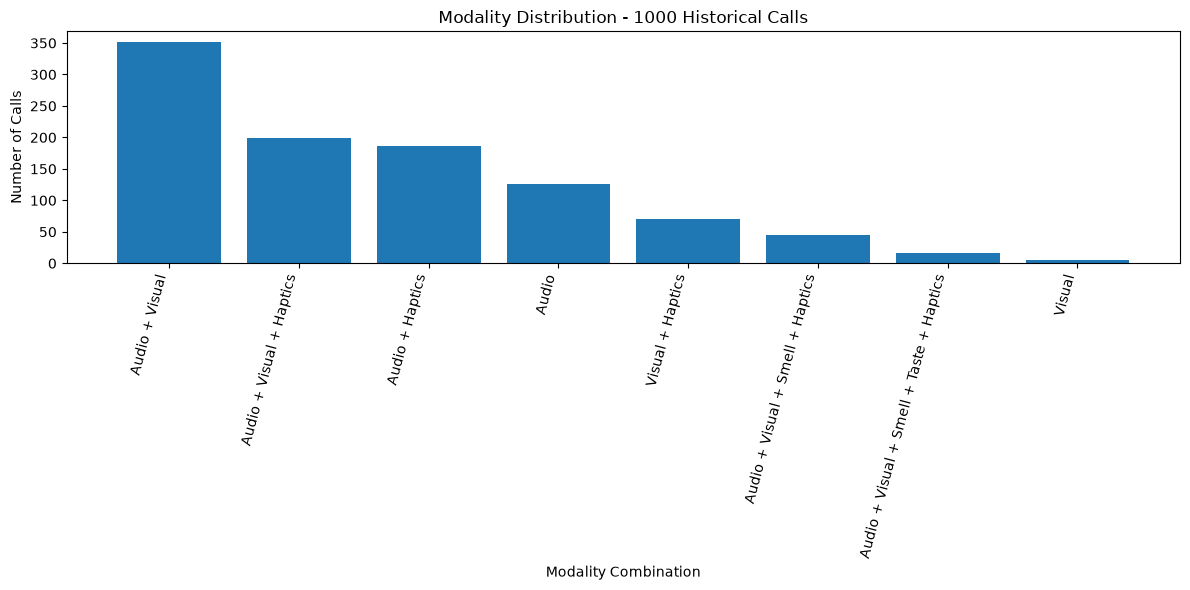



15.3 FINAL SGD MODEL CONFIGURATION


,Model Property,Value
0,Classifier,SGDClassifier
1,Loss function,log_loss
2,Training epochs,20
3,Random state,42
4,Averaged SGD,True
5,Predictive context inputs,"Location, Relationship, Time, Day"
6,Engineered feature,Context_Combination
7,Possible output classes,31
8,Evaluation method,Approximately 80% training / 20% held-out testing
9,Incremental retraining batch,10




15.4 FINAL HELD-OUT PERFORMANCE


,Metric,Result
0,Historical dataset size,1000.000000
1,Held-out test calls,200.000000
2,Correct predictions,172.000000
3,Incorrect predictions,28.000000
4,Accuracy (%),86.000000
5,Macro Precision,0.890168
6,Macro Recall,0.831988
7,Macro F1,0.854535
8,Weighted Precision,0.861264
9,Weighted Recall,0.860000




15.5 CUMULATIVE DATASET PERFORMANCE


...

,precision,recall,f1-score,support
Audio,0.827586,0.960000,0.888889,25.00
Audio + Haptics,0.944444,0.918919,0.931507,37.00
Audio + Visual,0.849315,0.885714,0.867133,70.00
Audio + Visual + Haptics,0.820513,0.800000,0.810127,40.00
Audio + Visual + Smell + Haptics,0.833333,0.555556,0.666667,9.00
Audio + Visual + Smell + Taste + Haptics,1.000000,0.750000,0.857143,4.00
Visual,1.000000,1.000000,1.000000,1.00
Visual + Haptics,0.846154,0.785714,0.814815,14.00
accuracy,0.860000,0.860000,0.860000,0.86
macro avg,0.890168,0.831988,0.854535,200.00




15.7 INDIVIDUAL MODALITY PERFORMANCE


,Modality,Precision,Recall,F1,Actual Positive Calls,Predicted Positive Calls
0,Audio,0.983871,0.989189,0.986523,185,186
1,Visual,0.977778,0.956522,0.967033,138,135
2,Smell,1.000000,0.692308,0.818182,13,9
3,Taste,1.000000,0.750000,0.857143,4,3
4,Haptics,0.948454,0.884615,0.915423,104,97




15.8 CONFUSION MATRIX


,Audio,Audio + Haptics,Audio + Visual,Audio + Visual + Haptics,Audio + Visual + Smell + Haptics,Audio + Visual + Smell + Taste + Haptics,Visual,Visual + Haptics
Audio,24,0,1,0,0,0,0,0
Audio + Haptics,1,34,1,0,0,0,0,1
Audio + Visual,3,0,62,4,0,0,0,1
Audio + Visual + Haptics,1,0,7,32,0,0,0,0
Audio + Visual + Smell + Haptics,0,0,1,3,5,0,0,0
Audio + Visual + Smell + Taste + Haptics,0,0,0,0,1,3,0,0
Visual,0,0,0,0,0,0,1,0
Visual + Haptics,0,2,1,0,0,0,0,11


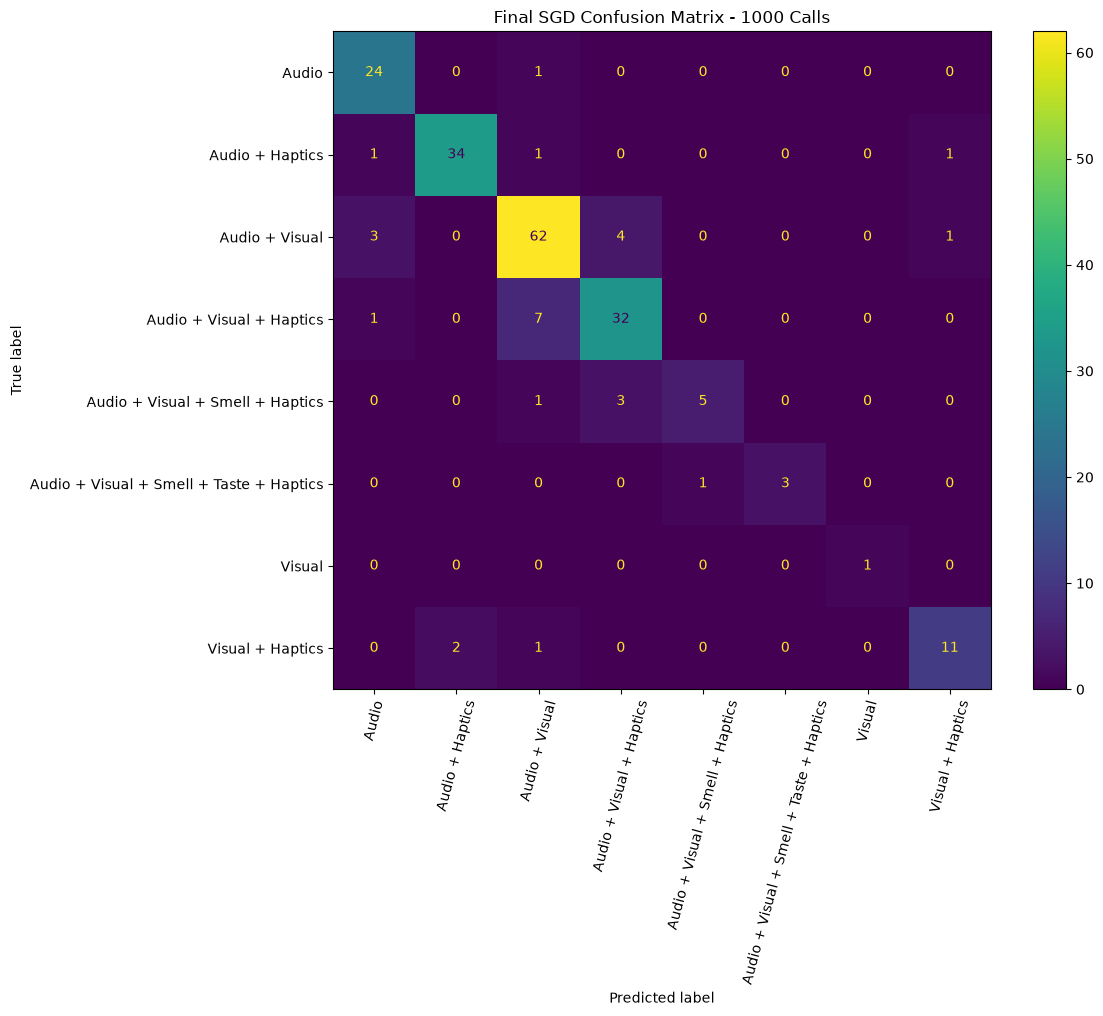



15.9 ERROR ANALYSIS


,Location,Relationship,Time,Day,Actual,Predicted,Model Probability (%),Correct
0,Home,Colleague,Night,Weekend,Audio + Visual + Haptics,Audio + Visual,99.423633,False
1,Home,Acquaintance,Night,Weekend,Audio + Visual + Haptics,Audio + Visual,98.597115,False
2,Travel,Friend,Afternoon,Weekday,Audio + Haptics,Visual + Haptics,64.748348,False
3,Social,Colleague,Evening,Weekday,Audio + Visual,Audio + Visual + Haptics,86.545723,False
4,Travel,Friend,Morning,Weekday,Visual + Haptics,Audio + Haptics,99.669983,False
5,Home,Acquaintance,Evening,Weekend,Audio + Visual + Haptics,Audio + Visual,99.616054,False
6,Home,Family,Evening,Weekend,Audio + Visual,Audio + Visual + Haptics,94.005002,False
7,Social,Family,Evening,Weekday,Audio + Visual + Smell + Haptics,Audio + Visual + Haptics,96.095765,False
8,Travel,Family,Afternoon,Weekend,Visual + Haptics,Audio + Haptics,94.847055,False
9,Work,Friend,Morning,Weekend,Audio + Visual,Audio,97.841409,False



Most common classification errors:



,Actual,Predicted,Errors
0,Audio + Visual + Haptics,Audio + Visual,7
1,Audio + Visual,Audio + Visual + Haptics,4
2,Audio + Visual,Audio,3
3,Audio + Visual + Smell + Haptics,Audio + Visual + Haptics,3
4,Visual + Haptics,Audio + Haptics,2
5,Audio,Audio + Visual,1
6,Audio + Haptics,Audio,1
7,Audio + Haptics,Audio + Visual,1
8,Audio + Haptics,Visual + Haptics,1
9,Audio + Visual,Visual + Haptics,1




15.10 PERFORMANCE BY CONTEXT VARIABLE

Performance by Location:



...


Performance by Day:



,Day,Test Calls,Accuracy (%),Macro Precision,Macro Recall,Macro F1
0,Weekday,93,87.096774,0.700067,0.703813,0.701581
1,Weekend,107,85.046729,0.891865,0.854872,0.868355




15.11 CONTEXT AMBIGUITY


,Measure,Result
0,Observed contexts,128.00000
1,Conflicting contexts,77.00000
2,Conflicting contexts (%),60.15625
3,Calls in conflicting contexts,676.00000
4,Calls affected (%),67.60000
5,Exact-context majority consistency (%),86.30000




15.12 DATASET-SIZE PERFORMANCE COMPARISON


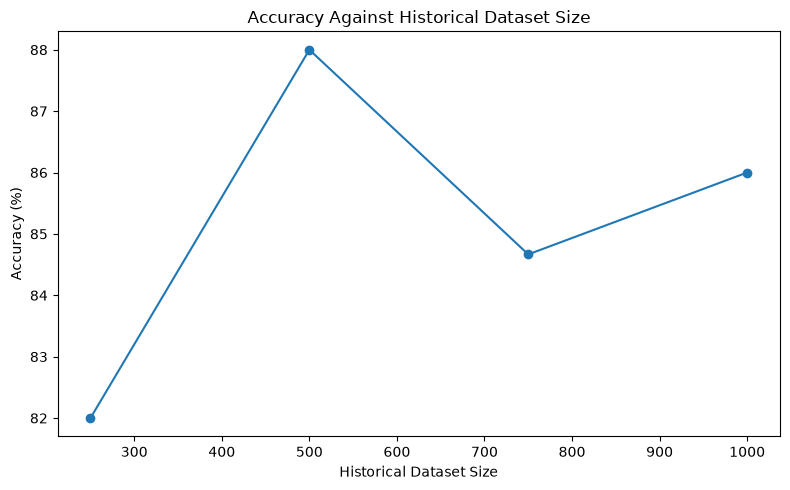

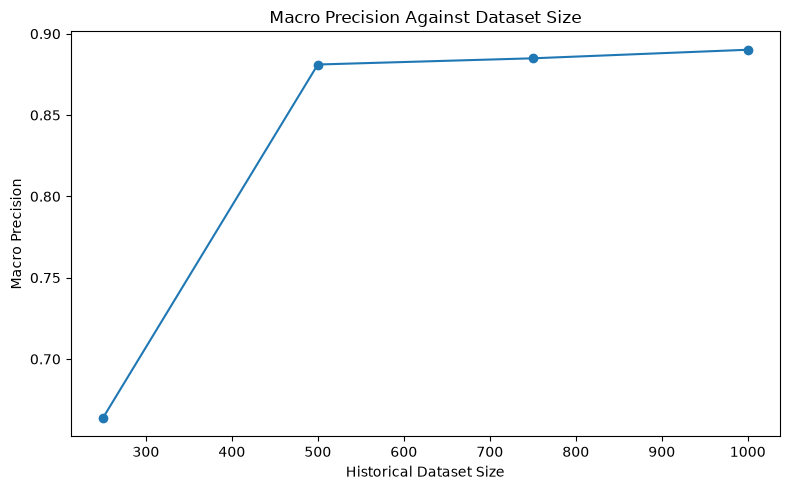

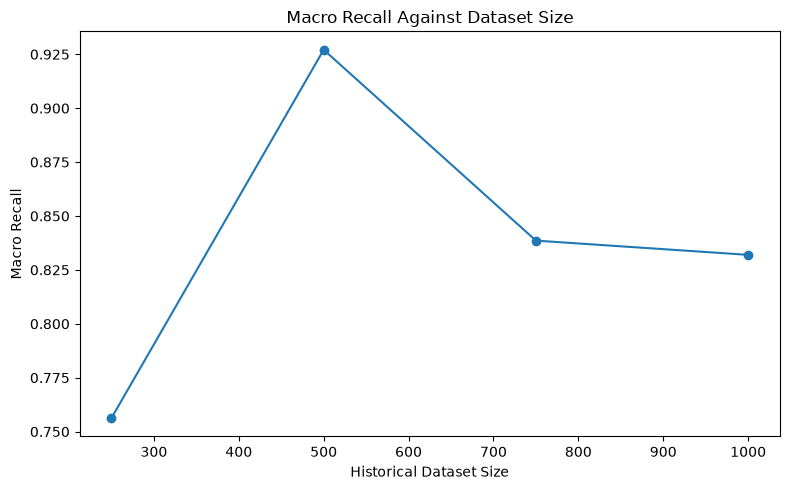

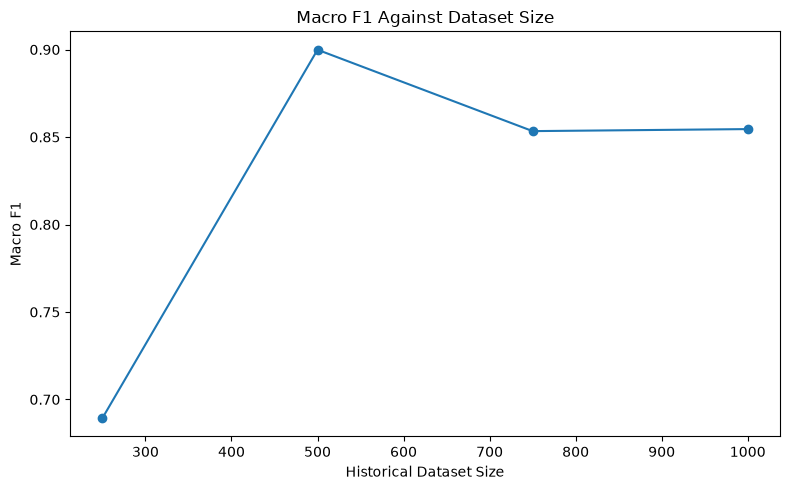



15.13 INCREMENTAL LEARNING STATUS


,Measure,Result
0,Original historical calls,1000
1,Current deployment history,2010
2,New calls incorporated,1010
3,Retraining batch size,10
4,Retraining events,101
5,Calls waiting in buffer,6
6,Calls needed for next retraining,4




15.14 FINAL THESIS RESULTS SUMMARY

Dataset size: 1000
Training calls: 800
Test calls: 200
Observed contexts: 128 / 128
Observed classes: 8 / 31

FINAL SGD PERFORMANCE
Accuracy: 86.00%
Macro Precision: 0.8902
Macro Recall: 0.8320
Macro F1: 0.8545
Weighted Precision: 0.8613
Weighted Recall: 0.8600
Weighted F1: 0.8581

Correct predictions: 172
Incorrect predictions: 28

Context-conflict statistics:
Conflicting contexts: 77
Calls affected by conflicting contexts: 67.60%
Context-majority consistency: 86.30%


FINAL SGD THESIS RESULTS COMPLETE

Results saved to:
C:\Users\slaye\final_sgd_thesis_results


In [63]:
# ============================================================
# SECTION 15: FINAL SGD THESIS RESULTS
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    hamming_loss,
    jaccard_score
)


# ============================================================
# 15.0 RESULTS DIRECTORY
# ============================================================

RESULTS_DIRECTORY = Path(
    "final_sgd_thesis_results"
)

RESULTS_DIRECTORY.mkdir(
    exist_ok=True
)


def print_results_heading(
    number,
    title
):

    print(
        "\n\n============================================================"
    )

    print(
        f"{number} {title}"
    )

    print(
        "============================================================"
    )


def save_table(
    table,
    filename,
    index=False
):

    table.to_csv(

        RESULTS_DIRECTORY
        /
        filename,

        index=index

    )


# ============================================================
# 15.1 DATASET CHARACTERISTICS
# ============================================================

print_results_heading(
    "15.1",
    "DATASET CHARACTERISTICS"
)


total_calls = len(
    historical_data
)


training_calls = len(
    training_data
)


testing_calls = len(
    testing_data
)


unique_contexts = (

    historical_data[
        MODEL_INPUT_FEATURES
    ]

    .drop_duplicates()

    .shape[0]

)


possible_contexts = (

    len(LOCATIONS)

    *

    len(RELATIONSHIPS)

    *

    len(TIMES)

    *

    len(DAYS)

)


observed_classes = (

    historical_data[
        "Modalities"
    ]

    .nunique()

)


dataset_summary = pd.DataFrame({

    "Measure": [

        "Historical calls",

        "Training calls",

        "Held-out test calls",

        "Training percentage",

        "Test percentage",

        "Context input variables",

        "Possible full contexts",

        "Observed full contexts",

        "Possible modality combinations",

        "Observed modality combinations",

        "Minimum duration",

        "Maximum duration",

        "Average duration",

        "Earliest timestamp",

        "Latest timestamp"

    ],

    "Result": [

        total_calls,

        training_calls,

        testing_calls,

        round(
            training_calls
            /
            total_calls
            *
            100,
            2
        ),

        round(
            testing_calls
            /
            total_calls
            *
            100,
            2
        ),

        len(
            MODEL_INPUT_FEATURES
        ),

        possible_contexts,

        unique_contexts,

        len(
            VALID_COMBINATIONS
        ),

        observed_classes,

        round(
            historical_data[
                "Duration_Minutes"
            ].min(),
            2
        ),

        round(
            historical_data[
                "Duration_Minutes"
            ].max(),
            2
        ),

        round(
            historical_data[
                "Duration_Minutes"
            ].mean(),
            2
        ),

        historical_data[
            "Timestamp"
        ].min(),

        historical_data[
            "Timestamp"
        ].max()

    ]

})


display(
    dataset_summary
)


save_table(

    dataset_summary,

    f"dataset_summary_{total_calls}.csv"

)


# ============================================================
# 15.2 MODALITY-COMBINATION DISTRIBUTION
# ============================================================

print_results_heading(
    "15.2",
    "MODALITY-COMBINATION DISTRIBUTION"
)


class_distribution = (

    historical_data[
        "Modalities"
    ]

    .value_counts()

    .rename_axis(
        "Modality Combination"
    )

    .reset_index(
        name="Calls"
    )

)


class_distribution[
    "Percentage (%)"
] = (

    class_distribution[
        "Calls"
    ]

    /

    total_calls

    *

    100

)


display(
    class_distribution
)


save_table(

    class_distribution,

    f"class_distribution_{total_calls}.csv"

)


plt.figure(
    figsize=(12, 6)
)


plt.bar(

    class_distribution[
        "Modality Combination"
    ],

    class_distribution[
        "Calls"
    ]

)


plt.xlabel(
    "Modality Combination"
)


plt.ylabel(
    "Number of Calls"
)


plt.title(

    f"Modality Distribution - "
    f"{total_calls} Historical Calls"

)


plt.xticks(
    rotation=75,
    ha="right"
)


plt.tight_layout()


plt.savefig(

    RESULTS_DIRECTORY
    /
    f"modality_distribution_{total_calls}.png",

    dpi=300,

    bbox_inches="tight"

)


plt.show()


# ============================================================
# 15.3 FINAL SGD MODEL CONFIGURATION
# ============================================================

print_results_heading(
    "15.3",
    "FINAL SGD MODEL CONFIGURATION"
)


model_configuration = pd.DataFrame({

    "Model Property": [

        "Classifier",

        "Loss function",

        "Training epochs",

        "Random state",

        "Averaged SGD",

        "Predictive context inputs",

        "Engineered feature",

        "Possible output classes",

        "Evaluation method",

        "Incremental retraining batch"

    ],

    "Value": [

        "SGDClassifier",

        "log_loss",

        TRAINING_EPOCHS,

        RANDOM_STATE,

        True,

        (
            "Location, Relationship, "
            "Time, Day"
        ),

        "Context_Combination",

        len(
            VALID_COMBINATIONS
        ),

        "Approximately 80% training / 20% held-out testing",

        NEW_CALL_BATCH_SIZE

    ]

})


display(
    model_configuration
)


save_table(

    model_configuration,

    f"model_configuration_{total_calls}.csv"

)


# ============================================================
# 15.4 FINAL HELD-OUT PERFORMANCE
# ============================================================

print_results_heading(
    "15.4",
    "FINAL HELD-OUT PERFORMANCE"
)


results_accuracy = accuracy_score(

    y_test,

    final_predictions

)


# ============================================================
# PRECISION
# ============================================================

results_macro_precision = precision_score(

    y_test,

    final_predictions,

    average="macro",

    zero_division=0

)


results_weighted_precision = precision_score(

    y_test,

    final_predictions,

    average="weighted",

    zero_division=0

)


# ============================================================
# RECALL
# ============================================================

results_macro_recall = recall_score(

    y_test,

    final_predictions,

    average="macro",

    zero_division=0

)


results_weighted_recall = recall_score(

    y_test,

    final_predictions,

    average="weighted",

    zero_division=0

)


# ============================================================
# F1
# ============================================================

results_macro_f1 = f1_score(

    y_test,

    final_predictions,

    average="macro",

    zero_division=0

)


results_weighted_f1 = f1_score(

    y_test,

    final_predictions,

    average="weighted",

    zero_division=0

)


correct_predictions = int(

    np.sum(

        y_test.to_numpy()

        ==

        final_predictions

    )

)


incorrect_predictions = (

    len(
        y_test
    )

    -

    correct_predictions

)


performance_summary = pd.DataFrame({

    "Metric": [

        "Historical dataset size",

        "Held-out test calls",

        "Correct predictions",

        "Incorrect predictions",

        "Accuracy (%)",

        "Macro Precision",

        "Macro Recall",

        "Macro F1",

        "Weighted Precision",

        "Weighted Recall",

        "Weighted F1",

        "Average model probability (%)"

    ],

    "Result": [

        total_calls,

        len(
            y_test
        ),

        correct_predictions,

        incorrect_predictions,

        results_accuracy
        *
        100,

        results_macro_precision,

        results_macro_recall,

        results_macro_f1,

        results_weighted_precision,

        results_weighted_recall,

        results_weighted_f1,

        np.mean(
            prediction_scores
        )

    ]

})


display(
    performance_summary
)


save_table(

    performance_summary,

    f"performance_summary_{total_calls}.csv"

)


# ============================================================
# 15.5 SAVE CUMULATIVE DATASET COMPARISON RESULT
#
# Running the notebook with 250, 500, 750 and 1000 calls
# automatically builds one comparison table.
# ============================================================

print_results_heading(
    "15.5",
    "CUMULATIVE DATASET PERFORMANCE"
)


COMPARISON_FILE = (

    RESULTS_DIRECTORY
    /
    "cumulative_dataset_performance.csv"

)


current_dataset_result = pd.DataFrame({

    "Historical Calls": [
        total_calls
    ],

    "Training Calls": [
        training_calls
    ],

    "Test Calls": [
        testing_calls
    ],

    "Observed Contexts": [
        unique_contexts
    ],

    "Observed Classes": [
        observed_classes
    ],

    "Accuracy (%)": [
        results_accuracy
        *
        100
    ],

    "Macro Precision": [
        results_macro_precision
    ],

    "Macro Recall": [
        results_macro_recall
    ],

    "Macro F1": [
        results_macro_f1
    ],

    "Weighted Precision": [
        results_weighted_precision
    ],

    "Weighted Recall": [
        results_weighted_recall
    ],

    "Weighted F1": [
        results_weighted_f1
    ]

})


# ------------------------------------------------------------
# LOAD EXISTING RESULTS IF THEY EXIST
# ------------------------------------------------------------

if COMPARISON_FILE.exists():


    cumulative_results = pd.read_csv(

        COMPARISON_FILE

    )


    # Remove an older result for the same dataset size
    # so rerunning the notebook does not create duplicates.

    cumulative_results = (

        cumulative_results[

            cumulative_results[
                "Historical Calls"
            ]

            !=

            total_calls

        ]

    )


    cumulative_results = pd.concat(

        [

            cumulative_results,

            current_dataset_result

        ],

        ignore_index=True

    )


else:


    cumulative_results = (

        current_dataset_result.copy()

    )


# ------------------------------------------------------------
# KEEP RESULTS IN DATASET-SIZE ORDER
# ------------------------------------------------------------

cumulative_results = (

    cumulative_results

    .sort_values(
        "Historical Calls"
    )

    .reset_index(
        drop=True
    )

)


cumulative_results.to_csv(

    COMPARISON_FILE,

    index=False

)


display(
    cumulative_results
)


print(
    "\nEach time you run the notebook with another "
    "dataset size, this table is updated automatically."
)


# ============================================================
# 15.6 PER-CLASS PRECISION, RECALL AND F1
# ============================================================

print_results_heading(
    "15.6",
    "PER-CLASS PRECISION, RECALL AND F1"
)


classification_report_table = (

    pd.DataFrame(

        classification_report(

            y_test,

            final_predictions,

            output_dict=True,

            zero_division=0

        )

    )

    .transpose()

)


display(
    classification_report_table
)


save_table(

    classification_report_table,

    f"classification_report_{total_calls}.csv",

    index=True

)


# ============================================================
# 15.7 INDIVIDUAL MODALITY PRECISION, RECALL AND F1
# ============================================================

print_results_heading(
    "15.7",
    "INDIVIDUAL MODALITY PERFORMANCE"
)


MODALITY_NAMES = [

    "Audio",

    "Visual",

    "Smell",

    "Taste",

    "Haptics"

]


def convert_to_modality_matrix(
    labels
):


    matrix = []


    for label in labels:


        selected_modalities = [

            item.strip()

            for item

            in str(
                label
            ).split("+")

        ]


        matrix.append([

            1

            if modality
            in selected_modalities

            else 0

            for modality
            in MODALITY_NAMES

        ])


    return np.array(
        matrix
    )


actual_modality_matrix = (

    convert_to_modality_matrix(

        y_test.to_numpy()

    )

)


predicted_modality_matrix = (

    convert_to_modality_matrix(

        final_predictions

    )

)


modality_results = []


for index, modality in enumerate(
    MODALITY_NAMES
):


    modality_results.append({

        "Modality":
            modality,

        "Precision":

            precision_score(

                actual_modality_matrix[
                    :,
                    index
                ],

                predicted_modality_matrix[
                    :,
                    index
                ],

                zero_division=0

            ),

        "Recall":

            recall_score(

                actual_modality_matrix[
                    :,
                    index
                ],

                predicted_modality_matrix[
                    :,
                    index
                ],

                zero_division=0

            ),

        "F1":

            f1_score(

                actual_modality_matrix[
                    :,
                    index
                ],

                predicted_modality_matrix[
                    :,
                    index
                ],

                zero_division=0

            ),

        "Actual Positive Calls":

            int(

                actual_modality_matrix[
                    :,
                    index
                ].sum()

            ),

        "Predicted Positive Calls":

            int(

                predicted_modality_matrix[
                    :,
                    index
                ].sum()

            )

    })


modality_performance = pd.DataFrame(

    modality_results

)


display(
    modality_performance
)


save_table(

    modality_performance,

    f"modality_performance_{total_calls}.csv"

)


# ============================================================
# 15.8 CONFUSION MATRIX
# ============================================================

print_results_heading(
    "15.8",
    "CONFUSION MATRIX"
)


confusion_labels = sorted(

    set(
        y_test.to_numpy()
    )

    |

    set(
        final_predictions
    )

)


confusion_values = confusion_matrix(

    y_test,

    final_predictions,

    labels=confusion_labels

)


confusion_table = pd.DataFrame(

    confusion_values,

    index=confusion_labels,

    columns=confusion_labels

)


display(
    confusion_table
)


save_table(

    confusion_table,

    f"confusion_matrix_{total_calls}.csv",

    index=True

)


plt.figure(
    figsize=(12, 10)
)


confusion_display = ConfusionMatrixDisplay(

    confusion_matrix=confusion_values,

    display_labels=confusion_labels

)


confusion_display.plot(

    ax=plt.gca(),

    xticks_rotation=75,

    values_format="d"

)


plt.title(

    f"Final SGD Confusion Matrix - "
    f"{total_calls} Calls"

)


plt.tight_layout()


plt.savefig(

    RESULTS_DIRECTORY
    /
    f"confusion_matrix_{total_calls}.png",

    dpi=300,

    bbox_inches="tight"

)


plt.show()


# ============================================================
# 15.9 ERROR ANALYSIS
# ============================================================

print_results_heading(
    "15.9",
    "ERROR ANALYSIS"
)


test_results = (

    testing_data[
        MODEL_INPUT_FEATURES
    ]

    .copy()

)


test_results[
    "Actual"
] = y_test.to_numpy()


test_results[
    "Predicted"
] = final_predictions


test_results[
    "Model Probability (%)"
] = prediction_scores


test_results[
    "Correct"
] = (

    test_results[
        "Actual"
    ]

    ==

    test_results[
        "Predicted"
    ]

)


incorrect_results = (

    test_results[

        test_results[
            "Correct"
        ]

        ==

        False

    ]

    .copy()

    .reset_index(
        drop=True
    )

)


display(
    incorrect_results
)


save_table(

    incorrect_results,

    f"incorrect_predictions_{total_calls}.csv"

)


if len(
    incorrect_results
) > 0:


    error_pairs = (

        incorrect_results

        .groupby(

            [
                "Actual",
                "Predicted"
            ]

        )

        .size()

        .reset_index(
            name="Errors"
        )

        .sort_values(

            "Errors",

            ascending=False

        )

        .reset_index(
            drop=True
        )

    )


else:


    error_pairs = pd.DataFrame(

        columns=[

            "Actual",

            "Predicted",

            "Errors"

        ]

    )


print(
    "\nMost common classification errors:\n"
)


display(
    error_pairs
)


save_table(

    error_pairs,

    f"error_pairs_{total_calls}.csv"

)


# ============================================================
# 15.10 PERFORMANCE BY CONTEXT VARIABLE
# ============================================================

print_results_heading(
    "15.10",
    "PERFORMANCE BY CONTEXT VARIABLE"
)


for context_variable in MODEL_INPUT_FEATURES:


    grouped_results = []


    for context_value, group in (

        test_results.groupby(
            context_variable
        )

    ):


        group_actual = group[
            "Actual"
        ]


        group_predicted = group[
            "Predicted"
        ]


        grouped_results.append({

            context_variable:
                context_value,

            "Test Calls":
                len(
                    group
                ),

            "Accuracy (%)":

                accuracy_score(

                    group_actual,

                    group_predicted

                )

                *
                100,

            "Macro Precision":

                precision_score(

                    group_actual,

                    group_predicted,

                    average="macro",

                    zero_division=0

                ),

            "Macro Recall":

                recall_score(

                    group_actual,

                    group_predicted,

                    average="macro",

                    zero_division=0

                ),

            "Macro F1":

                f1_score(

                    group_actual,

                    group_predicted,

                    average="macro",

                    zero_division=0

                )

        })


    context_performance = pd.DataFrame(

        grouped_results

    )


    print(
        f"\nPerformance by {context_variable}:\n"
    )


    display(
        context_performance
    )


    save_table(

        context_performance,

        (
            f"context_{context_variable.lower()}_"
            f"performance_{total_calls}.csv"
        )

    )


# ============================================================
# 15.11 CONTEXT AMBIGUITY
# ============================================================

print_results_heading(
    "15.11",
    "CONTEXT AMBIGUITY"
)


context_history = (

    historical_data[
        MODEL_INPUT_FEATURES
        +
        ["Modalities"]
    ]

    .copy()

)


context_history[
    "Context_Combination"
] = (

    context_history[
        "Location"
    ]

    + " | "

    + context_history[
        "Relationship"
    ]

    + " | "

    + context_history[
        "Time"
    ]

    + " | "

    + context_history[
        "Day"
    ]

)


ambiguity_rows = []


for context_name, group in (

    context_history.groupby(
        "Context_Combination"
    )

):


    output_counts = (

        group[
            "Modalities"
        ]

        .value_counts()

    )


    majority_count = int(

        output_counts.iloc[
            0
        ]

    )


    number_outputs = (

        group[
            "Modalities"
        ]

        .nunique()

    )


    ambiguity_rows.append({

        "Context":
            context_name,

        "Historical Calls":
            len(
                group
            ),

        "Distinct Outputs":
            number_outputs,

        "Conflicting Context":
            number_outputs > 1,

        "Most Common Output":
            output_counts.index[0],

        "Most Common Output Count":
            majority_count,

        "Consistency (%)":

            majority_count

            /

            len(
                group
            )

            *
            100

    })


context_ambiguity = pd.DataFrame(

    ambiguity_rows

)


conflicting_contexts = int(

    context_ambiguity[
        "Conflicting Context"
    ].sum()

)


calls_in_conflicting_contexts = int(

    context_ambiguity.loc[

        context_ambiguity[
            "Conflicting Context"
        ],

        "Historical Calls"

    ].sum()

)


context_majority_ceiling = (

    context_ambiguity[
        "Most Common Output Count"
    ].sum()

    /

    total_calls

    *
    100

)


ambiguity_summary = pd.DataFrame({

    "Measure": [

        "Observed contexts",

        "Conflicting contexts",

        "Conflicting contexts (%)",

        "Calls in conflicting contexts",

        "Calls affected (%)",

        "Exact-context majority consistency (%)"

    ],

    "Result": [

        len(
            context_ambiguity
        ),

        conflicting_contexts,

        conflicting_contexts
        /
        len(
            context_ambiguity
        )
        *
        100,

        calls_in_conflicting_contexts,

        calls_in_conflicting_contexts
        /
        total_calls
        *
        100,

        context_majority_ceiling

    ]

})


display(
    ambiguity_summary
)


save_table(

    ambiguity_summary,

    f"context_ambiguity_{total_calls}.csv"

)


# ============================================================
# 15.12 DATASET-SIZE PERFORMANCE FIGURES
#
# These figures become most useful after all four datasets
# have been run.
# ============================================================

print_results_heading(
    "15.12",
    "DATASET-SIZE PERFORMANCE COMPARISON"
)


if len(
    cumulative_results
) >= 2:


    # --------------------------------------------------------
    # ACCURACY
    # --------------------------------------------------------

    plt.figure(
        figsize=(8, 5)
    )


    plt.plot(

        cumulative_results[
            "Historical Calls"
        ],

        cumulative_results[
            "Accuracy (%)"
        ],

        marker="o"

    )


    plt.xlabel(
        "Historical Dataset Size"
    )


    plt.ylabel(
        "Accuracy (%)"
    )


    plt.title(
        "Accuracy Against Historical Dataset Size"
    )


    plt.tight_layout()


    plt.savefig(

        RESULTS_DIRECTORY
        /
        "dataset_size_accuracy.png",

        dpi=300,

        bbox_inches="tight"

    )


    plt.show()


    # --------------------------------------------------------
    # MACRO PRECISION
    # --------------------------------------------------------

    plt.figure(
        figsize=(8, 5)
    )


    plt.plot(

        cumulative_results[
            "Historical Calls"
        ],

        cumulative_results[
            "Macro Precision"
        ],

        marker="o"

    )


    plt.xlabel(
        "Historical Dataset Size"
    )


    plt.ylabel(
        "Macro Precision"
    )


    plt.title(
        "Macro Precision Against Dataset Size"
    )


    plt.tight_layout()


    plt.savefig(

        RESULTS_DIRECTORY
        /
        "dataset_size_macro_precision.png",

        dpi=300,

        bbox_inches="tight"

    )


    plt.show()


    # --------------------------------------------------------
    # MACRO RECALL
    # --------------------------------------------------------

    plt.figure(
        figsize=(8, 5)
    )


    plt.plot(

        cumulative_results[
            "Historical Calls"
        ],

        cumulative_results[
            "Macro Recall"
        ],

        marker="o"

    )


    plt.xlabel(
        "Historical Dataset Size"
    )


    plt.ylabel(
        "Macro Recall"
    )


    plt.title(
        "Macro Recall Against Dataset Size"
    )


    plt.tight_layout()


    plt.savefig(

        RESULTS_DIRECTORY
        /
        "dataset_size_macro_recall.png",

        dpi=300,

        bbox_inches="tight"

    )


    plt.show()


    # --------------------------------------------------------
    # MACRO F1
    # --------------------------------------------------------

    plt.figure(
        figsize=(8, 5)
    )


    plt.plot(

        cumulative_results[
            "Historical Calls"
        ],

        cumulative_results[
            "Macro F1"
        ],

        marker="o"

    )


    plt.xlabel(
        "Historical Dataset Size"
    )


    plt.ylabel(
        "Macro F1"
    )


    plt.title(
        "Macro F1 Against Dataset Size"
    )


    plt.tight_layout()


    plt.savefig(

        RESULTS_DIRECTORY
        /
        "dataset_size_macro_f1.png",

        dpi=300,

        bbox_inches="tight"

    )


    plt.show()


else:


    print(
        "Run the model on at least two cumulative datasets "
        "before plotting dataset-size trends."
    )


# ============================================================
# 15.13 INCREMENTAL LEARNING STATUS
# ============================================================

print_results_heading(
    "15.13",
    "INCREMENTAL LEARNING STATUS"
)


if (

    "final_training_history"
    in globals()

    and

    "final_new_call_buffer"
    in globals()

    and

    "final_retrain_count"
    in globals()

):


    new_calls_learned = (

        len(
            final_training_history
        )

        -

        BASE_DATASET_CALLS

    )


    incremental_summary = pd.DataFrame({

        "Measure": [

            "Original historical calls",

            "Current deployment history",

            "New calls incorporated",

            "Retraining batch size",

            "Retraining events",

            "Calls waiting in buffer",

            "Calls needed for next retraining"

        ],

        "Result": [

            BASE_DATASET_CALLS,

            len(
                final_training_history
            ),

            new_calls_learned,

            NEW_CALL_BATCH_SIZE,

            final_retrain_count,

            len(
                final_new_call_buffer
            ),

            NEW_CALL_BATCH_SIZE

            -

            len(
                final_new_call_buffer
            )

        ]

    })


    display(
        incremental_summary
    )


    save_table(

        incremental_summary,

        f"incremental_learning_{total_calls}.csv"

    )


# ============================================================
# 15.14 FINAL THESIS SUMMARY
# ============================================================

print_results_heading(
    "15.14",
    "FINAL THESIS RESULTS SUMMARY"
)


print(
    "\nDataset size:",
    total_calls
)


print(
    "Training calls:",
    training_calls
)


print(
    "Test calls:",
    testing_calls
)


print(
    "Observed contexts:",
    unique_contexts,
    "/",
    possible_contexts
)


print(
    "Observed classes:",
    observed_classes,
    "/",
    len(
        VALID_COMBINATIONS
    )
)


print(
    "\nFINAL SGD PERFORMANCE"
)


print(
    f"Accuracy: "
    f"{results_accuracy * 100:.2f}%"
)


print(
    f"Macro Precision: "
    f"{results_macro_precision:.4f}"
)


print(
    f"Macro Recall: "
    f"{results_macro_recall:.4f}"
)


print(
    f"Macro F1: "
    f"{results_macro_f1:.4f}"
)


print(
    f"Weighted Precision: "
    f"{results_weighted_precision:.4f}"
)


print(
    f"Weighted Recall: "
    f"{results_weighted_recall:.4f}"
)


print(
    f"Weighted F1: "
    f"{results_weighted_f1:.4f}"
)


print(
    "\nCorrect predictions:",
    correct_predictions
)


print(
    "Incorrect predictions:",
    incorrect_predictions
)


print(
    "\nContext-conflict statistics:"
)


print(
    "Conflicting contexts:",
    conflicting_contexts
)


print(
    f"Calls affected by conflicting contexts: "
    f"{calls_in_conflicting_contexts / total_calls * 100:.2f}%"
)


print(
    f"Context-majority consistency: "
    f"{context_majority_ceiling:.2f}%"
)


# ============================================================
# 15.15 COMPLETE
# ============================================================

print(
    "\n\n============================================================"
)

print(
    "FINAL SGD THESIS RESULTS COMPLETE"
)

print(
    "============================================================"
)


print(
    "\nResults saved to:"
)


print(
    RESULTS_DIRECTORY.resolve()
)

Current historical dataset: 1000 calls
Expected held-out predictions: 200

Using prediction table: final_test_results
Number of held-out predictions: 200


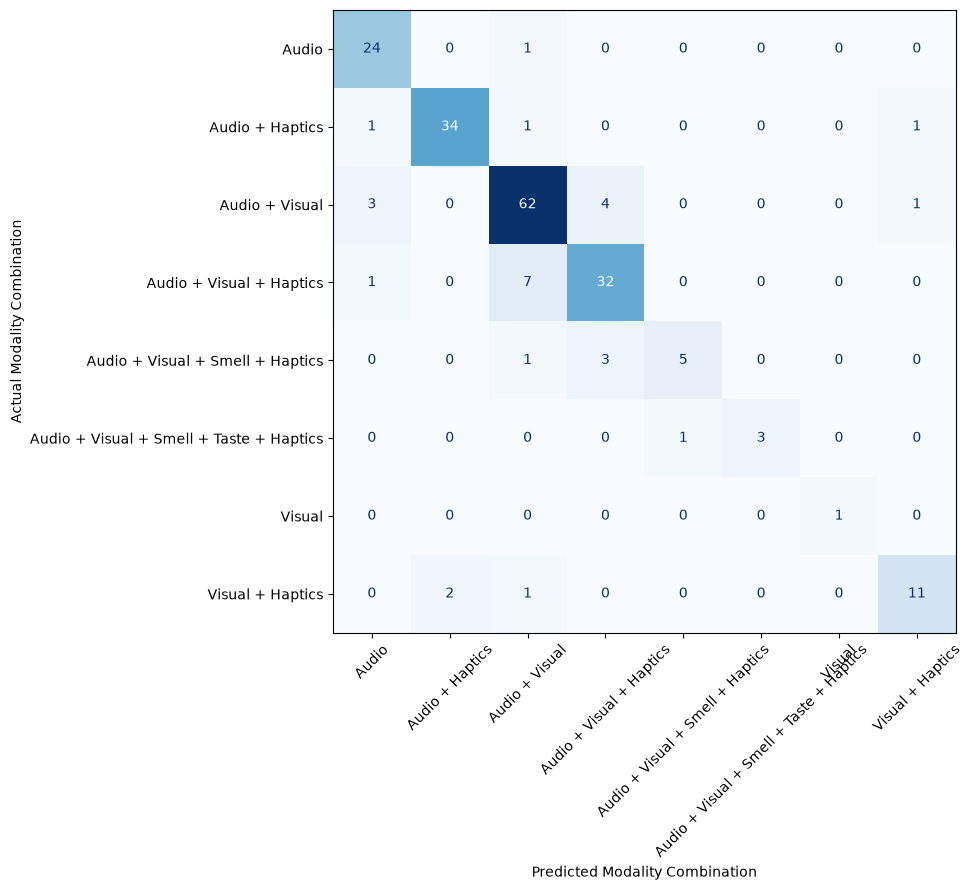


Confusion matrix saved as:
Figure_4_4_SGD_Confusion_Matrix_1000_Calls.png


In [64]:
# ============================================================
# FIGURE 4.4: FINAL SGD CONFUSION MATRIX
# DATASET-SIZE AGNOSTIC
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay
)


# ------------------------------------------------------------
# Determine current held-out test size
# ------------------------------------------------------------

expected_test_size = len(y_test)


print(
    "Current historical dataset:",
    len(historical_data),
    "calls"
)

print(
    "Expected held-out predictions:",
    expected_test_size
)


# ------------------------------------------------------------
# Find the DataFrame containing the current held-out
# SGD predictions
# ------------------------------------------------------------

prediction_candidates = []


for name, obj in list(globals().items()):

    if isinstance(
        obj,
        pd.DataFrame
    ):

        if (
            "Actual" in obj.columns
            and
            "Predicted" in obj.columns
        ):

            if len(obj) == expected_test_size:

                prediction_candidates.append(
                    (
                        name,
                        obj
                    )
                )


# ------------------------------------------------------------
# Prefer the final SGD result tables
# ------------------------------------------------------------

preferred_names = [

    "final_test_results",

    "test_results"

]


prediction_table_name = None
prediction_df = None


for preferred_name in preferred_names:

    for name, dataframe in prediction_candidates:

        if name == preferred_name:

            prediction_table_name = name

            prediction_df = dataframe

            break

    if prediction_df is not None:

        break


# ------------------------------------------------------------
# If preferred table was not found, use first valid candidate
# ------------------------------------------------------------

if (
    prediction_df is None
    and
    len(prediction_candidates) > 0
):

    prediction_table_name, prediction_df = (

        prediction_candidates[0]

    )


# ------------------------------------------------------------
# No matching table found
# ------------------------------------------------------------

if prediction_df is None:

    print(
        f"\nNo {expected_test_size}-row "
        "SGD prediction DataFrame was found."
    )


    print(
        "\nAvailable DataFrames containing "
        "Actual and Predicted columns:"
    )


    for name, obj in list(globals().items()):

        if isinstance(
            obj,
            pd.DataFrame
        ):

            if (
                "Actual" in obj.columns
                and
                "Predicted" in obj.columns
            ):

                print(
                    f"{name}: {len(obj)} rows"
                )


# ------------------------------------------------------------
# Use the matching SGD prediction table
# ------------------------------------------------------------

else:

    print(
        f"\nUsing prediction table: "
        f"{prediction_table_name}"
    )


    print(
        "Number of held-out predictions:",
        len(
            prediction_df
        )
    )


    # --------------------------------------------------------
    # Actual and predicted labels
    # --------------------------------------------------------

    y_true = prediction_df[
        "Actual"
    ]


    y_pred = prediction_df[
        "Predicted"
    ]


    # --------------------------------------------------------
    # Classes appearing in held-out results
    # --------------------------------------------------------

    labels = sorted(

        set(
            y_true
        )

        |

        set(
            y_pred
        )

    )


    # --------------------------------------------------------
    # Calculate confusion matrix
    # --------------------------------------------------------

    cm = confusion_matrix(

        y_true,

        y_pred,

        labels=labels

    )


    # --------------------------------------------------------
    # Plot
    # --------------------------------------------------------

    fig, ax = plt.subplots(

        figsize=(12, 9)

    )


    disp = ConfusionMatrixDisplay(

        confusion_matrix=cm,

        display_labels=labels

    )


    disp.plot(

        ax=ax,

        cmap="Blues",

        values_format="d",

        xticks_rotation=45,

        colorbar=False

    )


    ax.set_xlabel(
        "Predicted Modality Combination"
    )


    ax.set_ylabel(
        "Actual Modality Combination"
    )


    plt.tight_layout()


    # --------------------------------------------------------
    # Save automatically using current dataset size
    # --------------------------------------------------------

    output_filename = (

        f"Figure_4_4_SGD_Confusion_Matrix_"
        f"{len(historical_data)}_Calls.png"

    )


    plt.savefig(

        output_filename,

        dpi=300,

        bbox_inches="tight"

    )


    plt.show()


    print(
        "\nConfusion matrix saved as:"
    )


    print(
        output_filename
    )